---
# 1 Housekeeping
---

Here we:
- import the libraries we need (pandas for tables, numpy for numbers, matplotlib for plots)
- set the random seeds so every run gives the same results
- set the plot style and the three plot colours for the whole notebook

In [1]:
#-------------------------------------------------------------------------------
# random seed used everywhere in this notebook
seed = 42
# colour for points where the flame burned
burned_colour = 'orange'
# colour for points where the flame went out (a bright blue, since dark blue vanishes on black)
out_colour = 'dodgerblue'
# colour for points the model can't use
unusable_colour = 'grey'
#-------------------------------------------------------------------------------

# import pandas to work with tables (dataframes)
import pandas as pd
# import numpy for maths and random numbers
import numpy as np
# import python's built-in random module
import random
# import matplotlib to draw plots
import matplotlib.pyplot as plt

# fix numpy's random number generator so results repeat
np.random.seed(seed)
# fix python's random number generator so results repeat
random.seed(seed)

# use a dark background for every plot
plt.style.use("dark_background")

# confirm the setup ran
print("Libraries loaded, seed =", seed)

Libraries loaded, seed = 42


Here we:
- set **where every file lives**, in one place
- in Google Colab we mount Google Drive and use the project folder there, so the files (and the locked prediction registry) survive runtime resets
- outside Colab, the files are read from the notebook's own folder
- the calibration file is found under any of the names it is usually saved as (NASA's download name, or a shortened one)

In [2]:
#-------------------------------------------------------------------------------
# project folder in Google Drive (used when running in Colab)
drive_folder = '/content/drive/MyDrive/flame-in-freefall'
# file names
bass2_file = 'PSI-25_Experimental table_BASS-II.csv'
calibration_names = ['PSI-25_Reference Data_Fan calibration data.xlsx', 'Fan calibration data.xlsx',
                     'Fan_calibration_data.xlsx']
points_file_name = 'olson_test_points.csv'
registry_file_name = 'prediction_registry.csv'
#-------------------------------------------------------------------------------

# import the module for file paths
import os

# in Colab: mount Google Drive and work from the project folder; elsewhere: work from this folder
try:
    from google.colab import drive
    drive.mount('/content/drive')
    data_folder = drive_folder
except ImportError:
    data_folder = '.'

# full path of a file in the data folder
def in_folder(name):
    return os.path.join(data_folder, name)

# the calibration file: the first of the usual names that exists
calibration_path = next((in_folder(n) for n in calibration_names if os.path.exists(in_folder(n))),
                        in_folder(calibration_names[0]))

# print where everything is read from and written to
print("Data folder:", os.path.abspath(data_folder))
print("Calibration file:", calibration_path, "| found:", os.path.exists(calibration_path))
print("Registry file:", in_folder(registry_file_name), "| exists:", os.path.exists(in_folder(registry_file_name)))

Mounted at /content/drive
Data folder: /content/drive/MyDrive/flame-in-freefall
Calibration file: /content/drive/MyDrive/flame-in-freefall/Fan calibration data.xlsx | found: True
Registry file: /content/drive/MyDrive/flame-in-freefall/prediction_registry.csv | exists: True


Here we:
- set how pandas prints tables, so we see every column and long text cells aren't hidden

In [3]:
#-------------------------------------------------------------------------------
# how many characters of a text cell to show before cutting it off
max_text_width = 60
# how wide (in characters) a printed table may be
print_width = 200
#-------------------------------------------------------------------------------

# show every column instead of hiding some behind "..."
pd.set_option("display.max_columns", None)
# let printed tables use the full width of the screen
pd.set_option("display.width", print_width)
# cut very long text cells after this many characters
pd.set_option("display.max_colwidth", max_text_width)

# confirm the display settings ran
print("Display settings applied")

Display settings applied


---
# 2 Load the BASS-II test table
---

Here we:
- read the CSV with every cell kept as text, exactly as NASA typed it
- stop pandas from silently turning words like "none" into missing values
- tidy the column names (they have doubled and trailing spaces)
- drop the blank line at the end of the file

In [4]:
#-------------------------------------------------------------------------------
# the BASS-II CSV, in the data folder (set in Housekeeping)
file_name = in_folder(bass2_file)
#-------------------------------------------------------------------------------

# load the dataset into a pandas dataframe, keeping every cell as raw text
raw = pd.read_csv(file_name, dtype=str, keep_default_na=False)

# squash repeated spaces in each column name and trim the ends
raw.columns = [" ".join(c.split()) for c in raw.columns]

# keep only rows where at least one cell is not empty (removes the blank last line)
raw = raw[(raw != "").any(axis=1)].reset_index(drop=True)

# print how many rows (tests) and columns we have
print("Rows (tests):", raw.shape[0], "| Columns:", raw.shape[1])

Rows (tests): 129 | Columns: 17


Here we:
- list every column name with its position number

In [5]:
#-------------------------------------------------------------------------------
# nothing to tweak here: this cell only lists the columns
show_columns = True
#-------------------------------------------------------------------------------

# go through each column with its position number and print it
if show_columns:
    for i, c in enumerate(raw.columns):
        print(f"{i:2d}  {c}")

 0  PI
 1  Test #
 2  Date
 3  GMT
 4  Sample #
 5  Fuel Sample Material
 6  Flow restrictor
 7  Fan display
 8  Air display
 9  Radiometer gain (1000 250 50 10)
10  Total Frames Shot
11  Calibrated initial O2 % by vol
12  Calibrated final O2 % by vol
13  Initial CO2 % by vol
14  Final CO2 % by vol
15  Initial CO (ppm)
16  Final CO (ppm)


**Finding:** BASS-II's as-run table has 129 tests and 17 columns. There is **no outcome column**: whether the flame burned or went out is only written as notes inside the flow columns, so outcomes have to be read by hand.

---
# 3 What is in the table?
---

Here we:
- count how many tests each researcher (PI) ran

In [6]:
#-------------------------------------------------------------------------------
# column that holds the researcher's name
pi_column = 'PI'
#-------------------------------------------------------------------------------

# count the tests per PI and print the counts as a plain list
print(raw[pi_column].value_counts().to_string())

PI
T'ien              29
Olson              27
Fernandez-Pello    27
Bhattacharjee      22
Miller             20
Ferkul              4


**Finding:** Six researchers ran tests. Olson ran 27 tests on PMMA rods in concurrent flow (upstream ignition), which is the configuration we model.

Here we:
- count how often each fuel material appears
- this shows the material names are typed inconsistently (e.g. `3/8"clear rod` vs `3/8" clear rod`)

In [7]:
#-------------------------------------------------------------------------------
# column that holds the fuel material description
material_column = 'Fuel Sample Material'
#-------------------------------------------------------------------------------

# count the tests per material and print the counts as a plain list
print(raw[material_column].value_counts().to_string())

Fuel Sample Material
2 cm SIBAL                                17
1/4" clear rod                            15
1/4" black rod                            11
1 cm SIBAL                                 8
3/8" black rod                             7
3/8" clear rod                             5
1 cm wide 200 micron thick PMMA            5
0.5" black rod                             4
1/2" clear PMMA rod                        4
2 cm 100 micron thick PMMA                 3
Nomex natural (nomex III)                  3
2 cm   0.2 mm PMMA film                    2
2 cm   0.1 mm PMMA film                    2
5 mm thick PMMA   2 cm wide                2
1/4 black rod                              2
4 cm spherical section                     2
1 mm thick PMMA   2 cm wide                2
3/8"clear rod                              2
100 micron PMMA film   2 cm wide           1
2 cm wide   5 mm thick 1 sided PMMA        1
3 mm thick PMMA 1 sided    2 cm wide       1
1 mm thick PMMA   1 sided   2 cm  

**Finding:** The material names are typed inconsistently (e.g. `3/8"clear rod` vs `3/8" clear rod`, `1/4 blac rod`), so materials can't be grouped by exact text and are standardised by hand in Step 2.

Here we:
- show the raw rows for one PI, here Olson (the PMMA rod, concurrent-flow tests we plan to model)
- show only the columns that matter for the model: material, flow, oxygen

In [8]:
#-------------------------------------------------------------------------------
# which PI's tests to show
pi_to_show = 'Olson'
# which columns to show
columns_to_show = ['Test #', 'Fuel Sample Material', 'Flow restrictor', 'Fan display',
                   'Air display', 'Calibrated initial O2 % by vol', 'Calibrated final O2 % by vol']
#-------------------------------------------------------------------------------

# pick out the rows belonging to this PI
pi_rows = raw[raw['PI'] == pi_to_show]

# print how many tests this PI ran
print(pi_to_show, "ran", len(pi_rows), "tests\n")

# print those rows with only the chosen columns, without the row index
print(pi_rows[columns_to_show].to_string(index=False))

Olson ran 27 tests

Test # Fuel Sample Material Flow restrictor                                                                                    Fan display                               Air display Calibrated initial O2 % by vol Calibrated final O2 % by vol
    O1       1/4" clear rod               2                                                                                 89  62  50  41                           20  10  5  2  1                           22.2                         21.7
    O2       1/4" clear rod               2                                                                             .54 pot   0.45 pot                                         0                           22.2                         21.9
   O3a       1/4" clear rod               2                                                                                                                                     5  3                             18                           18
   O3b       1/4

**Finding:** Olson's notes mix measured airflow (cm/s), fan-display readings and control-knob (pot) settings, and outcomes appear as words like "ext", "out", "blowoff" and "no ign". Each test is a time-ordered sequence of flow settings, not a single measurement.

Here we:
- check each measurement column for cells that are not a plain number
- `pd.to_numeric(..., errors="coerce")` turns anything it can't read into a missing value, so those cells are the messy ones
- this is the list of problems Step 2 has to handle

In [9]:
#-------------------------------------------------------------------------------
# position of the first column to check (6 = 'Flow restrictor'; earlier columns are labels)
first_column_to_check = 6
# how many example messy values to print per column
n_examples = 8
#-------------------------------------------------------------------------------

# go through each measurement column
for c in raw.columns[first_column_to_check:]:
    # find the cells in this column that can't be read as a number
    bad = raw.loc[pd.to_numeric(raw[c], errors="coerce").isna(), c]
    # only report columns that actually have messy cells
    if len(bad):
        # print the column name, how many messy cells, and a few examples
        print(f"{c}: {len(bad)} cells, e.g. {bad.unique()[:n_examples].tolist()}")

Fan display: 110 cells, e.g. ['0.9   1.3   2.75', '1.4    incr to 10.0', '0.6   0.35', '1.7 (52)   1.25   0.9   0.6   0.4   0.35', '2.5 (59)   1.3   0.7   0.5   0.35', '3.5 (68)    1.7   1.25   0.9   0.6   0.4   0.35', 'pot 0.9   0.5 and down', '1.4 (50) incr to 10.0 pot']
Air display: 104 cells, e.g. ['3   5   approaching 10', '10   max', '2   <1', '5  4  3  2  1', '5   3   1   <1', '10   5  4  3  2  1', '5  3  2   ext', '3  0.5 pot   0.4 pot']
Radiometer gain (1000 250 50 10): 19 cells, e.g. ['250>50>250', '250>50', '50>250', '50   250', '250  50  250', '10   250', '250   50   250', '1000   250']
Total Frames Shot: 6 cells, e.g. ['none', '300+   +102', '10 postburn only', 'video']
Calibrated final O2 % by vol: 2 cells, e.g. ['none']
Initial CO2 % by vol: 2 cells, e.g. ['none']
Final CO2 % by vol: 6 cells, e.g. ['', 'none']
Initial CO (ppm): 3 cells, e.g. ['OR', 'none']
Final CO (ppm): 9 cells, e.g. ['', 'none', '>500', 'OR', 'over']


**Finding:** Every flow column is mostly free text (110 of 129 Fan display cells and 104 Air display cells are not plain numbers). The O₂ columns are clean apart from two "none" entries, which the O₂ rule in Step 2 handles.

---
# 4 Step 2: load the fan calibration
---

Here we:
- load NASA's fan calibration sheet exactly as a grid of cells (no header), so we can find each test day's block by position
- each test day has three columns: **Pot** (control-box knob), **Fan Display** (fan volts × 10) and **Air Display** (airflow in cm/s)

In [10]:
#-------------------------------------------------------------------------------
# the fan calibration file, in the data folder (found in Housekeeping)
cal_file_name = calibration_path
#-------------------------------------------------------------------------------

# load the calibration sheet as a raw grid, with no row treated as the header
cal_raw = pd.read_excel(cal_file_name, header=None)

# print the size of the grid
print("Calibration grid:", cal_raw.shape[0], "rows x", cal_raw.shape[1], "columns")

Calibration grid: 34 rows x 109 columns


Here we:
- walk across the row holding the dates; each date marks one test day's block (Pot | Fan Display | Air Display)
- walk down each block; every time we hit an `Air` header we move to the next restrictor section (0 → 1 → 2 restrictors)
- keep every row that has a fan reading, as one tidy table: date, restrictor, pot, fan, air
- skip column 1: that block is NASA's worked example of how to estimate flow, not a test day

In [11]:
#-------------------------------------------------------------------------------
# row of the grid that holds the dates
date_row = 2
# an 'Air' header above this row starts the 1-restrictor section, from this row on the 2-restrictor section
restrictor_2_start_row = 22
# columns to skip (NASA's worked example block)
skip_columns = [1]
#-------------------------------------------------------------------------------

# empty list to collect one dictionary per calibration reading
cal_rows = []

# go through every column of the date row
for col in range(cal_raw.shape[1]):
    # read the cell in the date row
    date_cell = cal_raw.iat[date_row, col]
    # skip empty cells and the example block
    if pd.isna(date_cell) or col in skip_columns:
        continue
    # skip text that isn't a date (the 'DATE' labels and NASA's example caption)
    if isinstance(date_cell, str) and not date_cell[0].isdigit():
        continue
    # turn the cell into a date; '7/31/2014 a.m.' needs its text removed first
    date = pd.to_datetime(str(date_cell).replace(' a.m.', '').replace(' p.m.', ''))
    # the Pot column sits just left of the date, Fan Display under it, Air Display just right
    pot_col, fan_col, air_col = col - 1, col, col + 1
    # the first section of every block (top of the sheet) is 'no restrictor'
    restrictor = 0
    # go down the rows below the date
    for row in range(date_row + 1, cal_raw.shape[0]):
        # read the three cells in this row
        pot, fan, air = cal_raw.iat[row, pot_col], cal_raw.iat[row, fan_col], cal_raw.iat[row, air_col]
        # an 'Air' header means a new restrictor section starts here
        if air == 'Air':
            restrictor = 1 if row < restrictor_2_start_row else 2
            continue
        # keep the row only if the fan reading is a number
        if isinstance(fan, (int, float)) and not pd.isna(fan):
            cal_rows.append({'date': date, 'restrictor': restrictor,
                             'pot': pot if isinstance(pot, (int, float)) else np.nan,
                             'fan': float(fan),
                             'air': air if isinstance(air, (int, float)) else np.nan})

# turn the list into a dataframe
cal = pd.DataFrame(cal_rows)

# print how many readings we found and on how many days
print(len(cal), "calibration readings on", cal['date'].nunique(), "test days")

537 calibration readings on 24 test days


Here we:
- print one day's restrictor-2 calibration so we can see what it maps
- this answers *pot → cm/s or fan → cm/s?*: it holds **both** links: pot → fan display (a fixed knob table) and fan display → airflow (measured that day)

In [12]:
#-------------------------------------------------------------------------------
# which day to show
show_date = '2014-06-26'
# which restrictor section to show
show_restrictor = 2
#-------------------------------------------------------------------------------

# pick out that day's readings for that restrictor and print them
print(cal[(cal['date'] == show_date) & (cal['restrictor'] == show_restrictor)].to_string(index=False))

      date  restrictor  pot   fan  air
2014-06-26           2 10.0 122.0 37.0
2014-06-26           2  8.0 105.0 30.0
2014-06-26           2  6.0  88.5 23.0
2014-06-26           2  4.0  72.0 15.0
2014-06-26           2  2.0  55.0  8.0
2014-06-26           2  1.0  46.5  NaN
2014-06-26           2  0.5  42.0  NaN
2014-06-26           2  0.0  38.0  0.0


**Finding:** The calibration sheet links all three quantities: pot setting → fan display (a fixed knob table) and fan display → airflow, measured each day for each flow restrictor. 537 readings across 24 test days. Low settings (pot 0.5–1, fan ≤46.5 here) have no airflow reading, which is why some points can't be converted later.

---
# 5 Step 2: transcribe Olson's test points
---

Here we:
- write down, by hand, every flow setting in Olson's 27 tests, in the order they happened
- each point is `(test, kind, value, burned, outcome, note)`:
  - `kind` = `'air'` (measured cm/s), `'fan'` (fan display, convert), `'pot'` (knob setting, convert) or `'none'` (no number written)
  - `burned` = 1 if the flame was held there, 0 if it went out there
- the comment above each test copies NASA's raw text, so every point can be checked against the CSV
- tests O1 to O9

In [13]:
#-------------------------------------------------------------------------------
# nothing to tweak: this cell is a transcription of NASA's notes
transcription_part = 'O1 to O9'
#-------------------------------------------------------------------------------

# empty list that will hold every test point
points = []

# O1  Fan "89 62 50 41" | Air "20 10 5 2 1": five measured flows, no out word
points += [('O1','air',20,1,'held',''), ('O1','air',10,1,'held',''), ('O1','air',5,1,'held',''),
           ('O1','air',2,1,'held',''), ('O1','air',1,1,'held','')]
# O2  Fan ".54 pot 0.45 pot" | Air "0": flame held with the air display reading 0
points += [('O2','air',0,1,'held','pots .54 then .45; air display read 0')]
# O3a Air "5 3"
points += [('O3a','air',5,1,'held',''), ('O3a','air',3,1,'held','')]
# O3b Air "5 3 2 1 low": the final "low" has no number, so it is not a point
points += [('O3b','air',5,1,'held',''), ('O3b','air',3,1,'held',''), ('O3b','air',2,1,'held',''),
           ('O3b','air',1,1,'held','followed by "low" (no number, not used)')]
# O4  Fan "5 0.7 0.5 0.4 0.36 ext" | Air "5 down to ext": 5 cm/s, then pots, out at pot 0.36
points += [('O4','air',5,1,'held',''), ('O4','pot',0.7,1,'held',''), ('O4','pot',0.5,1,'held',''),
           ('O4','pot',0.4,1,'held',''), ('O4','pot',0.36,0,'extinguished','"ext"')]
# O5a Fan (pots) "1.3 2.7 1.3 0.7 0.45 4.0" | Air "5 10 5 2 0 (49 62 49 44 42)": 5 measured flows, then pot 4.0
points += [('O5a','air',5,1,'held','fan 49'), ('O5a','air',10,1,'held','fan 62'), ('O5a','air',5,1,'held','fan 49'),
           ('O5a','air',2,1,'held','fan 44'), ('O5a','air',0,1,'held','fan 42'), ('O5a','pot',4.0,1,'held','no air reading')]
# O5b Fan "1.3" | Air "49 5 cm/s"
points += [('O5b','air',5,1,'held','fan 49')]
# O6  Fan "5 .36 .32 .31 .305 out .275" | Air "see fan": 5 cm/s, then pots, out at pot .275
points += [('O6','air',5,1,'held','5 written in Fan display cell'), ('O6','pot',0.36,1,'held',''),
           ('O6','pot',0.32,1,'held',''), ('O6','pot',0.31,1,'held',''), ('O6','pot',0.305,1,'held',''),
           ('O6','pot',0.275,0,'extinguished','"out"')]
# O7  Fan "5 .36 .32 ..305 blowoff fan max 10": flow raised to pot 10, flame blew off
points += [('O7','air',5,1,'held','5 written in Fan display cell'), ('O7','pot',0.36,1,'held',''),
           ('O7','pot',0.32,1,'held',''), ('O7','pot',0.305,1,'held','NASA typed "..305"'),
           ('O7','pot',10,0,'blowoff','"blowoff fan max 10"')]
# O8a Fan "5 .36 .32 .31 extinguished"
points += [('O8a','air',5,1,'held','5 written in Fan display cell'), ('O8a','pot',0.36,1,'held',''),
           ('O8a','pot',0.32,1,'held',''), ('O8a','pot',0.31,0,'extinguished','"extinguished"')]
# O8b Fan "5 .36 .32 .31 blowoff fan pot 6.0"
points += [('O8b','air',5,1,'held','5 written in Fan display cell'), ('O8b','pot',0.36,1,'held',''),
           ('O8b','pot',0.32,1,'held',''), ('O8b','pot',0.31,1,'held',''),
           ('O8b','pot',6.0,0,'blowoff','"blowoff fan pot 6.0"')]
# O9  Fan "5 .36 .32 blowoff pt 4.0"
points += [('O9','air',5,1,'held','5 written in Fan display cell'), ('O9','pot',0.36,1,'held',''),
           ('O9','pot',0.32,1,'held',''), ('O9','pot',4.0,0,'blowoff','"blowoff pt 4.0"')]

# print how many points so far
print(len(points), "points transcribed so far")

48 points transcribed so far


Here we:
- continue the transcription: tests O10 to O15b

In [14]:
#-------------------------------------------------------------------------------
# nothing to tweak: this cell is a transcription of NASA's notes
transcription_part = 'O10 to O15b'
#-------------------------------------------------------------------------------

# O10 Fan "49 44 41 122 (1.3 0.7 0.4 0.36 0.32 10)" | Air "5 2 0 max": 3 measured, 2 pots, then fan 122 (max)
points += [('O10','air',5,1,'held','fan 49'), ('O10','air',2,1,'held','fan 44'), ('O10','air',0,1,'held','fan 41'),
           ('O10','pot',0.36,1,'held',''), ('O10','pot',0.32,1,'held',''),
           ('O10','fan',122,1,'held','air display "max"')]
# O11 Fan "ign 5 0.36 0.32 0.31 0.305 blowoff 6.0" | Air "5 down then blowoff" (black rod)
points += [('O11','air',5,1,'held',''), ('O11','pot',0.36,1,'held',''), ('O11','pot',0.32,1,'held',''),
           ('O11','pot',0.31,1,'held',''), ('O11','pot',0.305,1,'held',''),
           ('O11','pot',6.0,0,'blowoff','"blowoff 6.0"')]
# O12 Fan "pots 1.4 3 0.9 0.7" | Air "no ign at any flow": every setting tried, none ignited
points += [('O12','pot',1.4,0,'no ignition',''), ('O12','pot',3,0,'no ignition',''),
           ('O12','pot',0.9,0,'no ignition',''), ('O12','pot',0.7,0,'no ignition','')]
# O13a Fan (pots) "1.3 0.7 0.45 0.36 0.32 0.31" | Air "49 44 42 41 41 40.5 (5 2 0)": cells swapped, fan values with air in brackets
points += [('O13a','air',5,1,'held','fan 49'), ('O13a','air',2,1,'held','fan 44'), ('O13a','air',0,1,'held','fan 42'),
           ('O13a','fan',41,1,'held','pot 0.36'), ('O13a','fan',41,1,'held','pot 0.32'),
           ('O13a','fan',40.5,1,'held','pot 0.31')]
# O13b Fan "1.3 0.9" | Air "7 4? (49 ?)": NASA marked the 4 with a question mark
points += [('O13b','air',7,1,'held','fan 49'), ('O13b','air',4,1,'held','NASA wrote "4?"')]
# O14 Fan "52 and down" | Air "5 down to ext": the flow at extinction was not written down (black rod)
points += [('O14','air',5,1,'held',''), ('O14','none',np.nan,0,'extinguished','"down to ext": flow not recorded')]
# O15a Fan "57.5 47 42 41 (2.3 1.0 0.5 0.35 0.32)" | Air "5 0"
# the "0" is NASA's measured airflow at fan 47 (O18, same day, also read 0 at fan 47), so it is used instead of converting
points += [('O15a','air',5,1,'held','fan 57.5'), ('O15a','air',0,1,'held','fan 47, pot 1.0'), ('O15a','fan',42,1,'held','pot 0.5'),
           ('O15a','fan',41,1,'held','pot 0.35'), ('O15a','pot',0.32,1,'held','')]
# O15b Fan "57.5 42 41 40 (2.3 0.5 0.35 0.34 0.33 0.32 0.31 0.30 0.29 0.28 0.27)" | Air "5 0"
points += [('O15b','air',5,1,'held','fan 57.5'), ('O15b','fan',42,1,'held','pot 0.5'), ('O15b','fan',41,1,'held','pot 0.35'),
           ('O15b','fan',40,1,'held','pot 0.34')]
points += [('O15b','pot',p,1,'held','') for p in [0.33, 0.32, 0.31, 0.30, 0.29, 0.28, 0.27]]

# print how many points so far
print(len(points), "points transcribed so far")

90 points transcribed so far


Here we:
- finish the transcription: tests O16 to O22 (O20 to O22 were run in 2016 with no restrictor)

In [15]:
#-------------------------------------------------------------------------------
# nothing to tweak: this cell is a transcription of NASA's notes
transcription_part = 'O16 to O22'
#-------------------------------------------------------------------------------

# O16 Fan "60 (2.6)" | Air "5"
points += [('O16','air',5,1,'held','fan 60')]
# O17 Fan "49 46.5 44 42 41 72 decr (1.3 1.0 0.7 0.5 0.4 4.0 decr)" | Air "3 0 11": final "decr" has no number
points += [('O17','air',3,1,'held','fan 49'), ('O17','fan',46.5,1,'held',''), ('O17','fan',44,1,'held',''),
           ('O17','fan',42,1,'held',''), ('O17','fan',41,1,'held','air display read 0 around here'),
           ('O17','air',11,1,'held','fan 72; followed by "decr" (no number, not used)')]
# O18 Fan "57 51 47 72 51 72 51 47 (2.3 1.5 1.0 4.0 1.5 4.0 1.5 1.0)" | Air "5 2 0 11 2 11 2 0": eight matched pairs
for a, f in zip([5, 2, 0, 11, 2, 11, 2, 0], [57, 51, 47, 72, 51, 72, 51, 47]):
    points += [('O18', 'air', a, 1, 'held', 'fan ' + str(f))]
# O19 Fan "52 and down" | Air "5 down to ext": the flow at extinction was not written down
points += [('O19','air',5,1,'held',''), ('O19','none',np.nan,0,'extinguished','"down to ext": flow not recorded')]
# O20 Fan "49 (1.3 pot) pots 7 8 9 10" | Air "5 8 incr to max 38.5"
points += [('O20','air',5,1,'held',''), ('O20','air',8,1,'held',''), ('O20','air',38.5,1,'held','max flow')]
# O21 Fan "46 (pot 0.8) pot 7 10" | Air "incr to 28": only the final flow has a number
points += [('O21','air',28,1,'held','start flow at pot 0.8 not recorded')]
# O22 Fan "49 (pot 1.1) blowoff pot 5 out at fan 87" | Air "4 incr to 26.5"
points += [('O22','air',4,1,'held',''),
           ('O22','air',26.5,0,'blowoff','reading at end of the increase; air sensor lags about 1 min')]

# turn the list into a dataframe with named columns
pts = pd.DataFrame(points, columns=['test_id', 'kind', 'value', 'burned', 'outcome', 'note'])
# number the points inside each test in time order (0, 1, 2, ...)
pts['point_order'] = pts.groupby('test_id').cumcount()

# print the totals
print(len(pts), "points from", pts['test_id'].nunique(), "tests")

113 points from 27 tests


Here we:
- check the transcription is complete: every Olson test in the CSV has points, and no made-up test IDs crept in

In [16]:
#-------------------------------------------------------------------------------
# which PI's tests we transcribed
pi_transcribed = 'Olson'
#-------------------------------------------------------------------------------

# the set of test IDs in the CSV for this PI
csv_ids = set(raw.loc[raw['PI'] == pi_transcribed, 'Test #'])
# the set of test IDs in our transcription
our_ids = set(pts['test_id'])
# print anything missing from either side (both should be empty)
print("In CSV but not transcribed:", sorted(csv_ids - our_ids))
print("Transcribed but not in CSV:", sorted(our_ids - csv_ids))

In CSV but not transcribed: []
Transcribed but not in CSV: []


Here we:
- check which day O10 really ran: its Date says 22 July 2014, but its GMT day number (213) means 1 August
- the chamber gas carries over from one test to the next, so a test's **starting** O₂, CO₂ and CO should exactly match the **ending** values of the test run just before it
- we look for tests whose ending gas matches O10's starting gas (the test before) and whose starting gas matches O10's ending gas (the test after)
- we also check which of the two days has a restrictor-2 airflow calibration, since O10 used restrictor 2

In [17]:
#-------------------------------------------------------------------------------
# which test to check
test_to_check = 'O10'
# the two candidate dates: the Date column and the GMT day number
candidate_dates = ['2014-07-22', '2014-08-01']
#-------------------------------------------------------------------------------

# copy the label columns we need
gas = raw[['PI', 'Test #', 'Date', 'GMT', 'Flow restrictor']].copy()
# turn the start and end gas readings into numbers ("none", "OR" become missing)
gas['o2_start'] = pd.to_numeric(raw['Calibrated initial O2 % by vol'], errors='coerce')
gas['o2_end'] = pd.to_numeric(raw['Calibrated final O2 % by vol'], errors='coerce')
gas['co2_start'] = pd.to_numeric(raw['Initial CO2 % by vol'], errors='coerce')
gas['co2_end'] = pd.to_numeric(raw['Final CO2 % by vol'], errors='coerce')
gas['co_start'] = pd.to_numeric(raw['Initial CO (ppm)'], errors='coerce')
gas['co_end'] = pd.to_numeric(raw['Final CO (ppm)'], errors='coerce')

# the row for the test we are checking
me = gas[gas['Test #'] == test_to_check].iloc[0]

# tests that ENDED with exactly the gas this test STARTED with (the test run just before)
before = gas[(gas['o2_end'] == me['o2_start']) & (gas['co2_end'] == me['co2_start']) & (gas['co_end'] == me['co_start'])]
# tests that STARTED with exactly the gas this test ENDED with (the test run just after)
after = gas[(gas['o2_start'] == me['o2_end']) & (gas['co2_start'] == me['co2_end']) & (gas['co_start'] == me['co_end'])]

# print the test being checked
print(test_to_check, "| Date", me['Date'], "| GMT", me['GMT'],
      "| starts O2/CO2/CO =", me['o2_start'], me['co2_start'], me['co_start'],
      "| ends", me['o2_end'], me['co2_end'], me['co_end'])
# print the matching tests before and after
print("\nTest run just before (end gas = its start gas):")
print(before[['PI', 'Test #', 'Date', 'GMT', 'o2_end', 'co2_end', 'co_end']].to_string(index=False))
print("\nTest run just after (start gas = its end gas):")
print(after[['PI', 'Test #', 'Date', 'GMT', 'o2_start', 'co2_start', 'co_start']].to_string(index=False))

# for each candidate date, count the restrictor-2 calibration readings that have an airflow value
print("\nRestrictor-2 airflow calibration readings per candidate date:")
for d in candidate_dates:
    n = cal[(cal['date'] == d) & (cal['restrictor'] == 2)]['air'].notna().sum()
    print(" ", d, ":", n)

O10 | Date 7/22/2014 | GMT 213 | starts O2/CO2/CO = 16.7 1.61 94.0 | ends 16.1 2.1 287.0

Test run just before (end gas = its start gas):
             PI Test #      Date GMT  o2_end  co2_end  co_end
Fernandez-Pello    P19 7/22/2014 203    16.7     1.61    94.0

Test run just after (start gas = its end gas):
Empty DataFrame
Columns: [PI, Test #, Date, GMT, o2_start, co2_start, co_start]
Index: []

Restrictor-2 airflow calibration readings per candidate date:
  2014-07-22 : 8
  2014-08-01 : 0


**Finding:** O10's GMT day number (213 = 1 August) is a typo. Its starting gas (O₂ 16.7%, CO₂ 1.61%, CO 94 ppm) exactly matches the ending gas of P19 on **22 July**, so it ran straight after P19 that day. The calibration agrees: 22 July has 8 restrictor-2 airflow readings, 1 August has none.

---
# 6 Step 2: attach test details and oxygen
---

Here we:
- copy each test's details from the CSV onto its points: date, flow restrictor, material, start and end O₂
- add `rod_diameter_in` and `rod_colour` (clear/black) from the material text

In [18]:
#-------------------------------------------------------------------------------
# label for the material we are modelling
material_label = 'PMMA rod, concurrent flow'
# rod sizes as written in NASA's material text, and their diameters in inches
rod_sizes = {'1/4': 0.25, '3/8': 0.375, '1/2': 0.5}
#-------------------------------------------------------------------------------

# take the CSV columns we need and give them short names
details = raw[['Test #', 'Date', 'Flow restrictor', 'Fuel Sample Material',
               'Calibrated initial O2 % by vol', 'Calibrated final O2 % by vol']].copy()
details.columns = ['test_id', 'date', 'restrictor', 'material_raw', 'o2_start_raw', 'o2_end_raw']

# turn the date text (month/day/year) into real dates
details['date'] = pd.to_datetime(details['date'], format='%m/%d/%Y')
# turn the restrictor text into a whole number
details['restrictor'] = details['restrictor'].astype(int)

# join the details onto every point, matched by test ID
pts = pts.merge(details, on='test_id', how='left')

# give every point the same standard material label
pts['material'] = material_label
# find which rod size appears in the material text and look up its diameter
pts['rod_diameter_in'] = pts['material_raw'].apply(lambda m: next(d for s, d in rod_sizes.items() if s in m))
# mark the rod as black if the material text says black, otherwise clear
pts['rod_colour'] = np.where(pts['material_raw'].str.contains('black'), 'black', 'clear')

# print how many points per rod colour and diameter
print(pts.groupby(['rod_colour', 'rod_diameter_in']).size().to_string())

rod_colour  rod_diameter_in
black       0.250               8
clear       0.250              61
            0.375              27
            0.500              17


Here we:
- give each point an O₂ value by stepping evenly from the start O₂ (first point) to the end O₂ (last point)
- if the end O₂ is missing or impossible (higher than the start, or a drop bigger than `max_o2_drop`), every point gets the start O₂
- a single-point test just gets the start O₂
- `o2_source` records which rule was used

In [19]:
#-------------------------------------------------------------------------------
# largest believable O2 drop during one test, in % by volume (Olson's biggest real drop is about 1.3)
max_o2_drop = 3.0
#-------------------------------------------------------------------------------

# turn the start and end O2 text into numbers ("none" becomes missing)
pts['o2_start'] = pd.to_numeric(pts['o2_start_raw'], errors='coerce')
pts['o2_end'] = pd.to_numeric(pts['o2_end_raw'], errors='coerce')

# count the points in each test
pts['n_points'] = pts.groupby('test_id')['test_id'].transform('size')

# the drop in O2 over the test
drop = pts['o2_start'] - pts['o2_end']
# the end value is believable if it exists, is not above the start, and the drop is not too big
end_ok = pts['o2_end'].notna() & (drop >= 0) & (drop <= max_o2_drop)

# fraction of the way through the test (0 for the first point, 1 for the last)
fraction = np.where(pts['n_points'] > 1, pts['point_order'] / (pts['n_points'] - 1).clip(lower=1), 0)

# step evenly from start to end where we can, otherwise use the start value
pts['o2_pct'] = np.where(end_ok & (pts['n_points'] > 1),
                         pts['o2_start'] + fraction * (pts['o2_end'] - pts['o2_start']),
                         pts['o2_start'])

# record which rule set the O2 value
pts['o2_source'] = np.select([pts['n_points'] == 1, ~end_ok],
                             ['start (single point)', 'start (end O2 invalid)'],
                             default='stepped start to end')

# print how often each rule was used
print(pts['o2_source'].value_counts().to_string())

o2_source
stepped start to end    109
start (single point)      4


---
# 7 Step 2: convert pot and fan settings to airflow
---

Here we:
- write a function that turns a pot or fan setting into airflow (cm/s) using **that test's day and restrictor** from the calibration
- pot → fan display: interpolate the knob table (pot 0, 0.5, 1, 2, ... 10)
- fan display → airflow: interpolate that day's measured airflow, using only non-zero readings (NASA's note says not to use the zero-flow point)
- if the fan value falls outside the calibrated range we **don't guess**: airflow is left missing and the reason is recorded

In [20]:
#-------------------------------------------------------------------------------
# nothing to tweak: the rules come from NASA's calibration sheet
use_zero_flow_points = False
#-------------------------------------------------------------------------------

def convert_to_airflow(kind, value, date, restrictor):
    # pick out the calibration readings for this test's day and restrictor
    day = cal[(cal['date'] == date) & (cal['restrictor'] == restrictor)]
    # stop if that day/restrictor was never calibrated
    if day.empty:
        return np.nan, np.nan, 'no calibration for this day/restrictor'
    # a pot setting must first become a fan display value
    if kind == 'pot':
        # take the rows that have both a pot and a fan value, sorted by pot
        knob = day.dropna(subset=['pot']).sort_values('pot')
        # interpolate along the knob table to get the fan display value
        fan = float(np.interp(value, knob['pot'], knob['fan']))
    else:
        # a fan display value is used directly
        fan = float(value)
    # take the readings with a measured airflow, sorted by fan value
    flow = day.dropna(subset=['air']).sort_values('fan')
    # drop zero-flow readings unless told to keep them
    if not use_zero_flow_points:
        flow = flow[flow['air'] > 0]
    # refuse to extrapolate below the lowest calibrated fan value
    if fan < flow['fan'].min():
        return fan, np.nan, 'below calibration range'
    # refuse to extrapolate above the highest calibrated fan value
    if fan > flow['fan'].max():
        return fan, np.nan, 'above calibration range'
    # interpolate the airflow at this fan value
    return fan, float(np.interp(fan, flow['fan'], flow['air'])), 'converted'

# quick test: pot 6 (O8b's blowoff) on 26 June 2014 with restrictor 2
print(convert_to_airflow('pot', 6.0, pd.Timestamp('2014-06-26'), 2))

(88.5, 23.0, 'converted')


Here we:
- check the pot → fan step against pairs NASA actually wrote down during tests (pot and fan display read together)
- if our interpolation matches NASA's own readings, the conversion is trustworthy

In [21]:
#-------------------------------------------------------------------------------
# (test, date, pot, fan display NASA recorded) copied from the raw Fan display cells
nasa_pot_fan_pairs = [('O13a','2014-07-21',1.3,49), ('O13a','2014-07-21',0.7,44), ('O13a','2014-07-21',0.45,42),
                      ('O13a','2014-07-21',0.36,41), ('O13a','2014-07-21',0.32,41), ('O13a','2014-07-21',0.31,40.5),
                      ('O18','2014-07-28',2.3,57), ('O18','2014-07-28',1.5,51), ('O18','2014-07-28',1.0,47),
                      ('O18','2014-07-28',4.0,72), ('O15a','2014-07-28',0.35,41)]
#-------------------------------------------------------------------------------

# empty list for the comparison rows
check = []
# go through each recorded pair
for test, date, pot, fan_nasa in nasa_pot_fan_pairs:
    # convert the pot with our function (restrictor 2 for all of these tests)
    fan_ours, _, _ = convert_to_airflow('pot', pot, pd.Timestamp(date), 2)
    # store both values side by side
    check.append({'test': test, 'pot': pot, 'fan_nasa': fan_nasa, 'fan_ours': round(fan_ours, 2),
                  'difference': round(fan_ours - fan_nasa, 2)})

# print the comparison table
print(pd.DataFrame(check).to_string(index=False))

test  pot  fan_nasa  fan_ours  difference
O13a 1.30      49.0     49.40        0.40
O13a 0.70      44.0     44.30        0.30
O13a 0.45      42.0     42.05        0.05
O13a 0.36      41.0     41.24        0.24
O13a 0.32      41.0     40.88       -0.12
O13a 0.31      40.5     40.79        0.29
 O18 2.30      57.0     57.55        0.55
 O18 1.50      51.0     51.00        0.00
 O18 1.00      47.0     47.00        0.00
 O18 4.00      72.0     72.00        0.00
O15a 0.35      41.0     40.80       -0.20


**Finding:** Our pot → fan conversion matches the pot/fan pairs NASA wrote down during the tests to within 0.55 fan units (often exactly). That step is trustworthy.

Here we:
- check the fan → airflow step against (fan display, airflow) pairs NASA read **during** tests
- the gap between the two shows how uncertain converted airflow is, which is why converted points get less weight

In [22]:
#-------------------------------------------------------------------------------
# (test, date, fan display, airflow NASA measured) copied from the raw cells
nasa_fan_air_pairs = [('O18','2014-07-28',57,5), ('O18','2014-07-28',51,2), ('O18','2014-07-28',72,11),
                      ('O5a','2014-07-21',49,5), ('O5a','2014-07-21',62,10), ('O5a','2014-07-21',44,2),
                      ('O17','2014-07-22',49,3), ('O17','2014-07-22',72,11),
                      ('O10','2014-07-22',49,5), ('O10','2014-07-22',44,2)]
#-------------------------------------------------------------------------------

# empty list for the comparison rows
check = []
# go through each recorded pair
for test, date, fan, air_nasa in nasa_fan_air_pairs:
    # convert the fan value with our function (restrictor 2 for all of these tests)
    _, air_ours, status = convert_to_airflow('fan', fan, pd.Timestamp(date), 2)
    # store both values side by side
    check.append({'test': test, 'fan': fan, 'air_nasa': air_nasa,
                  'air_ours': round(air_ours, 1) if not np.isnan(air_ours) else np.nan,
                  'difference': round(air_ours - air_nasa, 1) if not np.isnan(air_ours) else np.nan,
                  'status': status})

# put the rows in a table and print it
check = pd.DataFrame(check)
print(check.to_string(index=False))
# print the typical size of the error
print("\nMean absolute difference:", round(check['difference'].abs().mean(), 2), "cm/s")

test  fan  air_nasa  air_ours  difference                  status
 O18   57         5       4.5        -0.5               converted
 O18   51         2       3.0         1.0               converted
 O18   72        11       8.0        -3.0               converted
 O5a   49         5       5.8         0.8               converted
 O5a   62        10      10.5         0.5               converted
 O5a   44         2       NaN         NaN below calibration range
 O17   49         3       4.1         1.1               converted
 O17   72        11      11.0         0.0               converted
 O10   49         5       4.1        -0.9               converted
 O10   44         2       NaN         NaN below calibration range

Mean absolute difference: 0.98 cm/s


**Finding:** Fan → airflow conversion is off by 0.98 cm/s on average and 3 cm/s at worst, compared with airflows NASA read during the tests. That uncertainty is why converted points get half weight. Two of NASA's own low readings (fan 44 → 2 cm/s) fall below the day's calibrated range, a preview of the problem at low flow.

Here we:
- run the conversion on every pot/fan point; measured (`'air'`) points keep their value
- add `airflow_source`: `measured`, `converted`, or `unknown`
- add `airflow_status` saying why a value is missing (below calibration range, flow not recorded, ...)

In [23]:
#-------------------------------------------------------------------------------
# nothing to tweak here
convert_kinds = ['pot', 'fan']
#-------------------------------------------------------------------------------

# empty lists for the new columns
fan_display, airflow, status = [], [], []
# go through every point
for _, p in pts.iterrows():
    if p['kind'] in convert_kinds:
        # pot or fan setting: convert it using that test's day and restrictor
        f, a, s = convert_to_airflow(p['kind'], p['value'], p['date'], p['restrictor'])
    elif p['kind'] == 'air':
        # measured airflow: keep it as it is
        f, a, s = np.nan, p['value'], 'measured'
    else:
        # no number written down
        f, a, s = np.nan, np.nan, 'flow not recorded'
    # store the three results
    fan_display.append(f); airflow.append(a); status.append(s)

# add the results as columns
pts['fan_display'] = fan_display
pts['airflow_cm_s'] = airflow
pts['airflow_status'] = status
# short label of where the airflow came from
pts['airflow_source'] = np.select([pts['kind'] == 'air', pts['kind'].isin(convert_kinds)],
                                  ['measured', 'converted'], default='unknown')

# print how many points ended up in each status
print(pts.groupby(['airflow_source', 'airflow_status']).size().to_string())

airflow_source  airflow_status         
converted       below calibration range    44
                converted                  12
measured        measured                   55
unknown         flow not recorded           2


**Finding:** Of 113 points, 55 have measured airflow and 12 were converted successfully. **44 sit below the lowest calibrated airflow** and 2 have no flow written down; we leave those blank rather than guess.

---
# 8 Step 2: flags, weights and the final table
---

Here we:
- mark which points the model can use: airflow known **and above 0** (we will take log(airflow), and log(0) doesn't exist) and O₂ known
- give each point a weight: 1 if measured, 0.5 if converted
- exception: O12's no-ignition points keep full weight; it failed at every flow it tried, so a small airflow error can't change its outcome
- record the reason any point can't be used

In [24]:
#-------------------------------------------------------------------------------
# model weight for points with measured airflow
weight_measured = 1.0
# model weight for points whose airflow was converted from pot/fan settings
weight_converted = 0.5
# outcomes that keep full weight even when converted (airflow barely matters to them)
full_weight_outcomes = ['no ignition']
#-------------------------------------------------------------------------------

# a point is usable if airflow is a positive number and O2 is known
pts['usable_for_model'] = (pts['airflow_cm_s'] > 0) & pts['o2_pct'].notna()

# reason a point can't be used (empty if it can)
pts['excluded_reason'] = np.select(
    [pts['airflow_cm_s'] == 0, pts['airflow_cm_s'].isna(), pts['o2_pct'].isna()],
    ['airflow 0 (log undefined)', pts['airflow_status'], 'O2 missing'], default='')

# weight by where the airflow came from: converted points get the lower weight...
pts['weight'] = np.where(pts['airflow_source'] == 'converted', weight_converted, weight_measured)
# ...unless their outcome is one that keeps full weight
pts.loc[pts['outcome'].isin(full_weight_outcomes), 'weight'] = weight_measured

# print usable vs not, split by burned/out
print(pts.groupby(['usable_for_model', 'burned']).size().unstack(fill_value=0).to_string())
# print the total weight of each class (what the model will actually 'feel')
print("\nTotal weight, usable points:")
print(pts[pts['usable_for_model']].groupby('burned')['weight'].sum().to_string())
# print why points were excluded
print("\nExcluded because:")
print(pts.loc[~pts['usable_for_model'], 'excluded_reason'].value_counts().to_string())

burned            0   1
usable_for_model       
False             5  48
True              9  51

Total weight, usable points:
burned
0     7.0
1    49.0

Excluded because:
excluded_reason
below calibration range      44
airflow 0 (log undefined)     7
flow not recorded             2


**Finding:** 60 points are usable: 51 burned, 9 went out. 53 are not: 44 below the calibration range, 7 at 0 cm/s (no log), 2 with no flow recorded. By weight the model sees 49 (burned) against 7 (flame-out): the outcome it most needs to learn is the rarest.

Here we:
- list every flame-out point, the rarest and most valuable rows, with all its flags

In [25]:
#-------------------------------------------------------------------------------
# columns to show
columns_to_show = ['test_id', 'point_order', 'rod_colour', 'o2_pct', 'airflow_cm_s', 'airflow_source',
                   'outcome', 'usable_for_model', 'excluded_reason', 'note']
#-------------------------------------------------------------------------------

# pick out the points where the flame went out and print them
print(pts.loc[pts['burned'] == 0, columns_to_show].round(2).to_string(index=False))

test_id  point_order rod_colour  o2_pct  airflow_cm_s airflow_source      outcome  usable_for_model         excluded_reason                                                        note
     O4            4      clear   13.60           NaN      converted extinguished             False below calibration range                                                       "ext"
     O6            5      clear   16.00           NaN      converted extinguished             False below calibration range                                                       "out"
     O7            4      clear   15.50          37.0      converted      blowoff              True                                                                "blowoff fan max 10"
    O8a            3      clear   15.30           NaN      converted extinguished             False below calibration range                                              "extinguished"
    O8b            4      clear   15.20          23.0      converted      blowof

**Finding:** Of 14 flame-outs, 9 are usable: 5 blowoffs at high airflow (15–37 cm/s) and 4 failed ignitions at 13.5% O₂ (O12). **All 5 low-flow flame-outs are lost** (3 below calibration, 2 with no flow recorded), so the data can't show the "starved flame" side. 8 of the 9 usable flame-outs rely on converted airflow.

Here we:
- write one plotting function, `plot_points`, so the same picture can be drawn at any O₂ range (full range for the pitch, zoomed for modelling)
- left panel: usable points on a log airflow axis; orange = burned, blue = went out; filled = measured airflow, hollow = converted
- right panel: unusable points in grey, grouped by why they can't be used; circle = burned, X = went out
- reference lines (ISS air, highest O₂ tested, Moon habitat air) are drawn only if they fall inside the chosen O₂ range
- the function returns the figure and left panel without showing them, so later steps can draw on top (e.g. the model's boundary)

In [26]:
#-------------------------------------------------------------------------------
# marker size
marker_size = 60
# how far to spread overlapping grey points sideways (0 = no spread)
jitter = 0.15
# reference O2 lines: (O2 %, label, line style)
# ISS cabin: 21% O2 at 14.7 psia
# Moon habitat air, two NASA set-points (NTRS 20240003211 and 20220013669):
#   34% O2 at 8.2 psia (exploration atmosphere, main target) and 26.5% O2 at 10.2 psia (the habitat's other mode)
reference_lines = [(21.0, 'ISS air (21%, 14.7 psia)', '--'),
                   (26.5, 'Moon habitat air, 10.2 psia mode (26.5%)', '--'),
                   (34.0, 'Moon habitat air, 8.2 psia exploration atmosphere (34%): main target', '--')]
# colour of the reference lines
reference_colour = 'white'
#-------------------------------------------------------------------------------

def plot_points(pts, o2_bottom, o2_top, title):
    # split the points into usable and unusable
    use = pts[pts['usable_for_model']]
    lost = pts[~pts['usable_for_model']]

    # make a figure with two panels side by side sharing the O2 axis; the left one is wider
    fig, (ax, ax2) = plt.subplots(1, 2, figsize=(11, 5), sharey=True, gridspec_kw={'width_ratios': [3, 1]})

    # LEFT PANEL: draw each combination of outcome and airflow source
    for burned, colour, label in [(1, burned_colour, 'burned'), (0, out_colour, 'went out')]:
        for source, filled in [('measured', True), ('converted', False)]:
            # pick the points in this group
            g = use[(use['burned'] == burned) & (use['airflow_source'] == source)]
            # draw them: filled markers for measured, hollow for converted
            ax.scatter(g['airflow_cm_s'], g['o2_pct'], s=marker_size,
                       facecolors=colour if filled else 'none', edgecolors=colour,
                       label=f"{label}, {source} ({len(g)})", zorder=3)
    # airflow on a log axis, as in the model
    ax.set_xscale('log')
    # axis labels and panel title
    ax.set_xlabel('Airflow (cm/s, log scale)')
    ax.set_ylabel('O$_2$ (% by volume)')
    ax.set_title(f'Usable points ({len(use)})')

    # RIGHT PANEL: one column per reason a point can't be used
    reasons = sorted(lost['excluded_reason'].unique())
    # random generator with the notebook seed, so the sideways spread is the same every run
    rng = np.random.default_rng(seed)
    for i, reason in enumerate(reasons):
        for burned, marker in [(1, 'o'), (0, 'X')]:
            # pick the unusable points with this reason and outcome
            g = lost[(lost['excluded_reason'] == reason) & (lost['burned'] == burned)]
            # spread them a little sideways so overlapping points stay visible
            x = i + rng.uniform(-jitter, jitter, len(g))
            # grey circles for burned; grey X for went out, drawn bigger, on top and outlined so the cluster can't hide them
            ax2.scatter(x, g['o2_pct'], s=marker_size if burned else 2.5 * marker_size,
                        color=unusable_colour, marker=marker, zorder=2 if burned else 3,
                        edgecolors='none' if burned else 'black', linewidths=0 if burned else 1.5,
                        label=('burned' if burned else 'went out') if i == 0 else None)
    # name each column after its reason, wrapped onto two lines
    ax2.set_xticks(range(len(reasons)))
    ax2.set_xticklabels([r.replace(' (', '\n(').replace(' range', '\nrange') for r in reasons], fontsize=8)
    # panel title and legend
    ax2.set_title(f'Unusable points ({len(lost)})')
    ax2.legend(fontsize=8)

    # the highest O2 in the data, worked out rather than typed in
    highest_tested = pts['o2_pct'].max()
    # all lines to draw: the reference lines plus a dotted line at the highest O2 tested
    lines = reference_lines + [(highest_tested, f'highest O$_2$ tested ({highest_tested:.1f}%)', ':')]
    for level, label, style in lines:
        # skip lines outside the chosen O2 range
        if not (o2_bottom <= level <= o2_top):
            continue
        # draw the line across both panels
        for a in (ax, ax2):
            a.axhline(level, color=reference_colour, linestyle=style, linewidth=1)
        # label just above the line (ISS label below it, where it covers no data points)
        offset = -0.03 * (o2_top - o2_bottom) if level == 21.0 else 0.01 * (o2_top - o2_bottom)
        ax.text(0.01, level + offset, label, transform=ax.get_yaxis_transform(),
                color=reference_colour, fontsize=9, va='top' if level == 21.0 else 'bottom')

    # set the O2 range
    ax.set_ylim(o2_bottom, o2_top)
    # overall title
    fig.suptitle(title)
    # return the figure and the left panel so the caller can add to them, then show
    return fig, ax

# confirm the function is ready
print("plot_points() defined")

plot_points() defined


Here we:
- draw the **full-range** plot (up to 36% O₂) for the pitch and video
- the empty band between the top of NASA's data and the Moon habitat lines is the gap our method targets

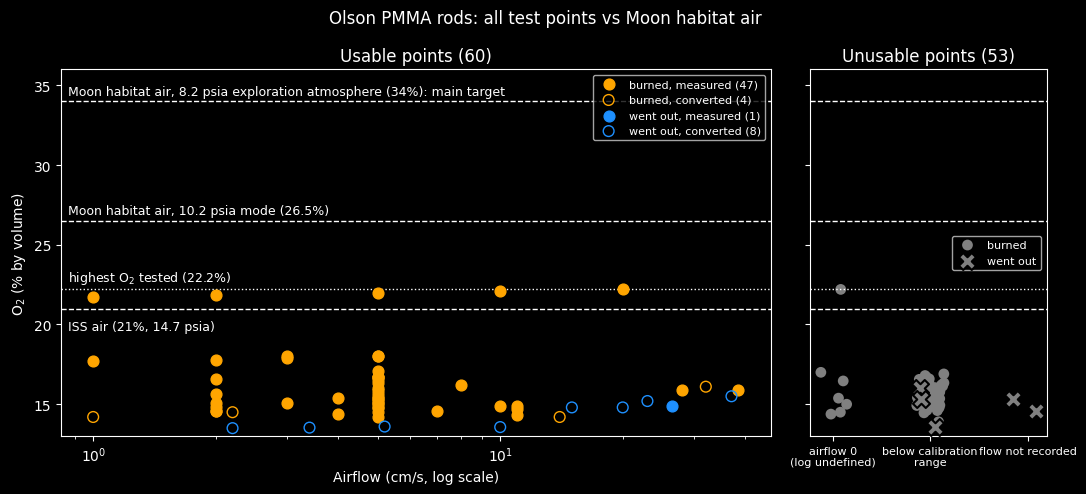

In [27]:
#-------------------------------------------------------------------------------
# O2 range for the pitch version
o2_bottom_full = 13
o2_top_full = 36
#-------------------------------------------------------------------------------

# draw the plot over the full O2 range
fig, ax = plot_points(pts, o2_bottom_full, o2_top_full, 'Olson PMMA rods: all test points vs Moon habitat air')
# put the legend in the empty upper-right area
ax.legend(fontsize=8, loc='upper right')
# stop labels overlapping
fig.tight_layout()
# show the plot, then close it
plt.show()
plt.close()

**Finding:** NASA's microgravity rod data tops out at 22.2% O₂. The two NASA habitat set-points, 26.5% (10.2 psia) and 34% (8.2 psia), sit **well above anything tested**: the empty band between them is the gap this project targets.

Here we:
- draw the **zoomed** plot (13–23% O₂) for the modelling steps, so the boundary between orange and blue is easy to see

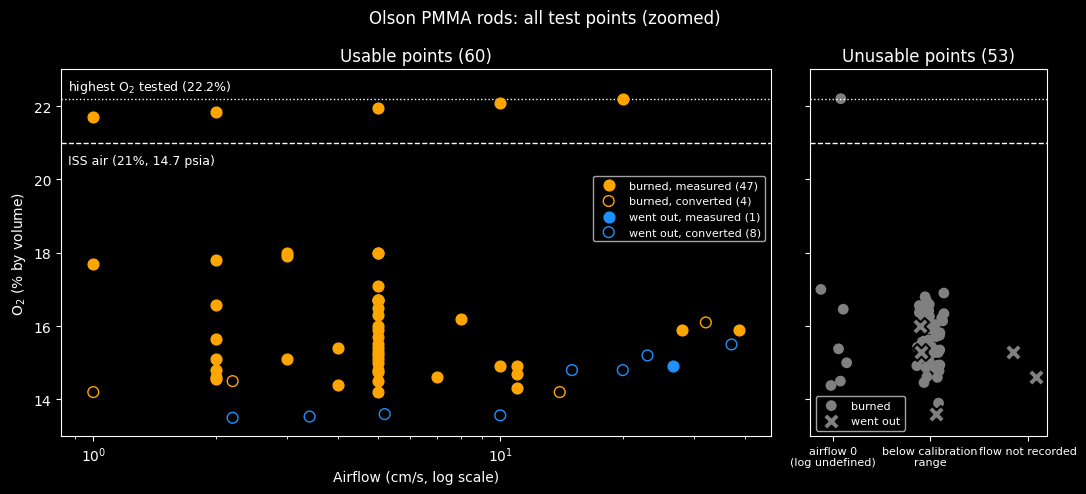

In [28]:
#-------------------------------------------------------------------------------
# O2 range for the modelling version
o2_bottom_zoom = 13
o2_top_zoom = 23
#-------------------------------------------------------------------------------

# draw the plot over the zoomed O2 range
fig, ax = plot_points(pts, o2_bottom_zoom, o2_top_zoom, 'Olson PMMA rods: all test points (zoomed)')
# put the legend in the empty band between the data and the top lines, on the right
ax.legend(fontsize=8, loc='center right', bbox_to_anchor=(1, 0.62))
# stop labels overlapping
fig.tight_layout()
# show the plot, then close it
plt.show()
plt.close()

**Finding:** The physics is visible before any model: flames survive above about 14–14.5% O₂ and fail to ignite at 13.5%. At high airflow they blow off unless there is more oxygen, so the burn/no-burn boundary rises with airflow.

---
# 9 Step 2: the pressure caveat
---

BASS-II only varied **oxygen percentage**. The table has no pressure column; the tests ran inside the ISS, so we take the pressure as ISS cabin pressure (~14.7 psia). Moon habitat air is different in **both** ways at once: more oxygen by percentage, but at lower pressure.

What a flame "feels" depends on both. One simple measure is the **oxygen partial pressure** = O₂ fraction × total pressure. The next cell works it out for the three atmospheres.

Sources for the Moon habitat set-points:
- NASA NTRS 20240003211, *Moon to Mars (M2M): Exploration Atmosphere*: 8.2 psia, 34% O₂
- NASA NTRS 20220013669, *Internal Layout of a Lunar Surface Habitat*: the habitat can run at 8.2 psia / 34% O₂ or 10.2 psia / 26.5% O₂

Here we:
- list the three atmospheres as (O₂ %, total pressure in psia)
- work out the oxygen partial pressure of each
- store the caveat that every prediction from this model must carry

In [29]:
#-------------------------------------------------------------------------------
# atmospheres to compare: name -> (O2 % by volume, total pressure in psia)
atmospheres = {'ISS cabin (BASS-II)': (21.0, 14.7),
               'Moon habitat, 10.2 psia mode': (26.5, 10.2),
               'Moon habitat, exploration atmosphere': (34.0, 8.2)}
# label attached to every model prediction from here on
prediction_caveat = 'at ISS cabin pressure (~14.7 psia); effect of reduced pressure not in the data'
#-------------------------------------------------------------------------------

# empty list for the table rows
rows = []
# go through each atmosphere
for name, (o2_pct, pressure_psia) in atmospheres.items():
    # oxygen partial pressure = oxygen fraction x total pressure
    rows.append({'atmosphere': name, 'O2 %': o2_pct, 'total psia': pressure_psia,
                 'O2 partial pressure (psia)': round(o2_pct / 100 * pressure_psia, 2)})

# print the comparison table
print(pd.DataFrame(rows).to_string(index=False))
# print the caveat every prediction will carry
print("\nEvery prediction is labelled:", prediction_caveat)

                          atmosphere  O2 %  total psia  O2 partial pressure (psia)
                 ISS cabin (BASS-II)  21.0        14.7                        3.09
        Moon habitat, 10.2 psia mode  26.5        10.2                        2.70
Moon habitat, exploration atmosphere  34.0         8.2                        2.79

Every prediction is labelled: at ISS cabin pressure (~14.7 psia); effect of reduced pressure not in the data


**Finding:** By partial pressure, habitat air has slightly less oxygen than the ISS (2.70–2.79 vs 3.09 psia). By fraction, which largely sets flame temperature, it has 26–62% more. How these combine in microgravity has never been tested: this is the gap our method targets.

Why "slightly less partial pressure" does **not** mean "safer":
- flame temperature is set mainly by the oxygen **fraction**: less nitrogen means less inert gas soaking up the flame's heat; lower pressure mostly changes how fast things react and mix
- NASA's own ground testing shows habitat air is a harder fire environment. At White Sands Test Facility, material flammability is measured at 8.2 psia, and NASA's Engineering and Safety Center reports that the standard meta-aramid and nylon webbings do not meet flammability requirements in elevated oxygen (NESC Technical Bulletin 26-05)
- a ground study on normoxic atmospheres (oxygen % raised while pressure drops, keeping partial pressure fixed) found that increasing oxygen concentration had a stronger influence than decreasing pressure on both flame spread and flame length, and cites microgravity flame-spread results showing more flammability in normoxic environments (IAASS 2021 conference paper, Univ. of Edinburgh, available via core.ac.uk)

Sources:
- NASA NESC, *TB 26-05 Webbings for Use in Elevated Oxygen Environments*: https://www.nasa.gov/centers-and-facilities/nesc/tb-26-05-webbings-for-use-in-elevated-oxygen-environments/
- IAASS 2021 paper on normoxic atmospheres: https://core.ac.uk/download/483871309.pdf

---
# 10 Step 2: save the table
---

Here we:
- put the columns in a sensible order and save the table as a CSV for Step 3
- every row carries its test ID and flags saying where each value came from

In [30]:
#-------------------------------------------------------------------------------
# name of the output file
output_file = in_folder(points_file_name)
#-------------------------------------------------------------------------------

# the columns to keep, in order
final_columns = ['test_id', 'point_order', 'date', 'restrictor', 'material', 'rod_diameter_in', 'rod_colour',
                 'o2_pct', 'o2_source', 'airflow_cm_s', 'airflow_source', 'airflow_status', 'kind', 'value',
                 'fan_display', 'burned', 'outcome', 'weight', 'usable_for_model', 'excluded_reason', 'note']
# keep those columns
points_table = pts[final_columns]
# save to CSV
points_table.to_csv(output_file, index=False)
# print the size and the first rows
print("Saved", len(points_table), "points to", output_file)
print(points_table.head(10).to_string(index=False))

Saved 113 points to /content/drive/MyDrive/flame-in-freefall/olson_test_points.csv
test_id  point_order       date  restrictor                  material  rod_diameter_in rod_colour  o2_pct            o2_source  airflow_cm_s airflow_source airflow_status kind  value  fan_display  burned outcome  weight  usable_for_model           excluded_reason                                  note
     O1            0 2014-02-18           2 PMMA rod, concurrent flow             0.25      clear  22.200 stepped start to end          20.0       measured       measured  air   20.0          NaN       1    held     1.0              True                                                                
     O1            1 2014-02-18           2 PMMA rod, concurrent flow             0.25      clear  22.075 stepped start to end          10.0       measured       measured  air   10.0          NaN       1    held     1.0              True                                                                
     O1    

---
# 11 Step 3: logistic regression on O₂ and log(airflow)
---

Here we:
- load the test-point table saved at the end of Step 2, so Step 3 works from the saved file
- keep only the points the model can use (airflow known and above 0, O₂ known)

In [31]:
#-------------------------------------------------------------------------------
# the table saved at the end of Step 2
points_file = in_folder(points_file_name)
#-------------------------------------------------------------------------------

# load the saved test points into a dataframe
data_all = pd.read_csv(points_file)
# keep only the usable points
data = data_all[data_all['usable_for_model']].reset_index(drop=True)

# print how many points, and how many of each outcome
print(len(data), "usable points:", (data['burned'] == 1).sum(), "burned,", (data['burned'] == 0).sum(), "went out")

60 usable points: 51 burned, 9 went out


Here we:
- write a function that turns a table of points into what the model needs:
  - `X`: the two inputs, O₂ % and the natural log of airflow (cm/s)
  - `y`: the answer, 1 = burned, 0 = went out
  - `w`: each point's weight from Step 2 (1 measured, 0.5 converted, 1 for O12's no-ignition)
- why log(airflow): the flows span 1 to 38 cm/s, and going from 1 to 2 cm/s matters about as much as going from 10 to 20

In [32]:
#-------------------------------------------------------------------------------
# names of the input columns
o2_column = 'o2_pct'
airflow_column = 'airflow_cm_s'
#-------------------------------------------------------------------------------

def make_xyw(d):
    # inputs: O2 and log of airflow, side by side as a two-column array
    X = np.column_stack([d[o2_column], np.log(d[airflow_column])])
    # answers: 1 = burned, 0 = went out
    y = d['burned'].to_numpy()
    # weights from Step 2
    w = d['weight'].to_numpy()
    # hand back all three
    return X, y, w

# build them for the usable points and print their sizes
X, y, w = make_xyw(data)
print("X:", X.shape, "| y:", y.shape, "| w:", w.shape)

X: (60, 2) | y: (60,) | w: (60,)


Here we:
- write a function that fits the model:
  1. **scale** both inputs to mean 0 and spread 1, so neither dominates just because of its units
  2. fit a **logistic regression**, which gives the probability of burning as an S-shaped function of a weighted sum of the inputs
- **no class weighting**: the model is fitted on the data as it is, so its probabilities stay honest (they are used for predictions, 90% ranges and the registry)
- the per-point weights from Step 2 are still used: they are about how reliable each point's airflow is, not about class balance
- the rare flame-outs are protected a different way, by moving the yes/no threshold (next cells), which is almost the same as balanced weighting but leaves the probabilities untouched
- note: the model is **one-sided in airflow**. It can learn "more flow → blowoff", but not "too little flow → starves". With no usable low-flow flame-outs (Step 2), that is all the data can support anyway

In [33]:
#-------------------------------------------------------------------------------
# regularisation strength: smaller = stronger pull of the coefficients towards 0 (scikit-learn's default is 1.0)
regularisation_C = 1.0
# class weighting: None keeps probabilities honest; 'balanced' would pull them towards flame-out
use_class_weight = None
#-------------------------------------------------------------------------------

# import the scaler, the logistic regression and the pipeline that chains them
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline

def fit_model(X, y, w):
    # chain the two steps: scale the inputs, then the logistic regression
    model = Pipeline([('scale', StandardScaler()),
                      ('logreg', LogisticRegression(C=regularisation_C, class_weight=use_class_weight))])
    # fit, passing each point's weight to the logistic regression step
    model.fit(X, y, logreg__sample_weight=w)
    # hand back the fitted model
    return model

# confirm the function is ready
print("fit_model() defined")

fit_model() defined


Here we:
- write a function that turns the fitted model back into **original units**, so the result reads as
  `log-odds of burning = b0 + b_o2 × O₂% + b_flow × ln(airflow)`
- the scaler changed the units; this undoes that by dividing by each input's spread and adjusting the intercept

In [34]:
#-------------------------------------------------------------------------------
# nothing to tweak: this is algebra
coefficient_names = ['b0 (intercept)', 'b_o2 (per % O2)', 'b_flow (per unit ln airflow)']
#-------------------------------------------------------------------------------

def original_units(model):
    # the scaler's mean and spread for each input
    mean, spread = model['scale'].mean_, model['scale'].scale_
    # the logistic regression's coefficients and intercept, in scaled units
    c, c0 = model['logreg'].coef_[0], model['logreg'].intercept_[0]
    # each coefficient in original units: divide by that input's spread
    b = c / spread
    # intercept in original units: remove the shift the scaler added
    b0 = c0 - np.sum(c * mean / spread)
    # hand back intercept, O2 coefficient, airflow coefficient
    return b0, b[0], b[1]

# confirm the function is ready
print("original_units() defined")

original_units() defined


Here we:
- write a function for the **yes/no threshold**: call a point "flame-out" when its probability of burning is below the **burn base rate**, not below 0.5
- burn base rate = weighted share of burns in the training data = Σ(weight × burned) / Σ(weight)
- why: in this data a burn is the normal outcome, so a point the model rates *less* likely to burn than an average point is a flame-out warning. Shifting the threshold this way is almost the same as balanced class weighting, but the probabilities stay honest

In [35]:
#-------------------------------------------------------------------------------
# nothing to tweak: the threshold comes from the data
threshold_rule = 'weighted burn base rate'
#-------------------------------------------------------------------------------

def burn_base_rate(y, w):
    # weighted share of burns: total weight of burned points / total weight of all points
    return float(np.sum(w * y) / np.sum(w))

# work it out for all usable points
threshold = burn_base_rate(y, w)
# print it, with the weights behind it
print(f"Burn base rate (yes/no threshold): {threshold:.3f}  "
      f"= {np.sum(w * y):.1f} burned weight / {np.sum(w):.1f} total weight")

Burn base rate (yes/no threshold): 0.875  = 49.0 burned weight / 56.0 total weight


Here we:
- fit the model on all usable points
- print the three numbers that define it, plus what they mean in plain terms:
  - how the odds of burning change for +1% O₂
  - how the odds change when airflow doubles

In [36]:
#-------------------------------------------------------------------------------
# airflow multiplier used to explain the airflow coefficient
airflow_factor = 2
#-------------------------------------------------------------------------------

# fit on all usable points
model = fit_model(X, y, w)
# get the coefficients in original units
b0, b_o2, b_flow = original_units(model)

# print the equation
print(f"log-odds(burn) = {b0:.2f} + {b_o2:.3f} x O2% + {b_flow:.3f} x ln(airflow)")
# odds multiplier for one extra % of O2
print(f"+1% O2 multiplies the odds of burning by {np.exp(b_o2):.2f}")
# odds multiplier when airflow is multiplied by airflow_factor
print(f"x{airflow_factor} airflow multiplies the odds of burning by {np.exp(b_flow * np.log(airflow_factor)):.2f}")
# remind the reader of the pressure caveat
print("\nAll predictions:", prediction_caveat)

log-odds(burn) = -10.25 + 0.909 x O2% + -0.885 x ln(airflow)
+1% O2 multiplies the odds of burning by 2.48
x2 airflow multiplies the odds of burning by 0.54

All predictions: at ISS cabin pressure (~14.7 psia); effect of reduced pressure not in the data


**Finding:** Oxygen dominates: each extra 1% O₂ multiplies the odds of burning by about 2.5. More airflow pushes towards blowoff: doubling the airflow roughly halves the odds (×0.54).

Here we:
- write a function that finds the **boundary**: for a given airflow, the O₂ % at which the model gives a chosen probability of burning
- from the equation above: `O₂ = (logit(p) − b0 − b_flow × ln(airflow)) / b_o2`, where `logit(p) = ln(p / (1 − p))`

In [37]:
#-------------------------------------------------------------------------------
# nothing to tweak: this is algebra
boundary_probabilities = [0.1, 0.5, 0.9]
#-------------------------------------------------------------------------------

def boundary_o2(airflow, p, b0, b_o2, b_flow):
    # log-odds that corresponds to probability p
    logit_p = np.log(p / (1 - p))
    # solve the model equation for O2
    return (logit_p - b0 - b_flow * np.log(airflow)) / b_o2

# example: the O2 on the yes/no line and the 50% line at 5 cm/s
print(f"yes/no line at 5 cm/s: {boundary_o2(5, threshold, b0, b_o2, b_flow):.2f}% O2")
print(f"50% line at 5 cm/s:    {boundary_o2(5, 0.5, b0, b_o2, b_flow):.2f}% O2")

yes/no line at 5 cm/s: 14.98% O2
50% line at 5 cm/s:    12.84% O2


Here we:
- write a function that greys out the **low-flow side** of a plot (below 2 cm/s)
- physics says the boundary should curve back up there (a flame starves without enough fresh oxygen flowing in), but we have **no usable flame-outs** in that region, so the model's straight line there is not supported by data
- the shading stops anyone reading the line as *flames burn at 13% O₂ if the fan is off*

In [38]:
#-------------------------------------------------------------------------------
# airflow (cm/s) below which we have no usable flame-out data (lowest usable flame-out is O12 at about 2.2 cm/s)
no_data_below_cm_s = 2.0
# shading colour and transparency
unknown_colour = 'grey'
unknown_alpha = 0.35
# label shown inside the shaded area
unknown_label = 'low-flow side:\nno flame-out data;\nthe boundary here\nis not known'
#-------------------------------------------------------------------------------

def shade_unknown(ax):
    # remember the current airflow range so shading doesn't change it
    left, right = ax.get_xlim()
    # shade from the left edge of the plot up to the no-data limit, behind the points
    ax.axvspan(left, no_data_below_cm_s, color=unknown_colour, alpha=unknown_alpha, zorder=0)
    # write the label near the top of the shaded area (x in data units, y as a fraction of the panel height)
    ax.text(np.sqrt(left * no_data_below_cm_s), 0.585, unknown_label, transform=ax.get_xaxis_transform(),
            ha='center', va='center', fontsize=8, color='white')
    # put the airflow range back exactly as it was
    ax.set_xlim(left, right)

# confirm the function is ready
print("shade_unknown() defined")

shade_unknown() defined


Here we:
- draw the zoomed plot from Step 2 and add the model's boundary lines on top
- solid white line = the **yes/no line** (probability of burning = the base rate); below it the model calls flame-out
- dashed lines = 10%, 50% and 90% chance of burning (the honest probabilities)
- the grey area below 2 cm/s is where the boundary is not known (no flame-out data)

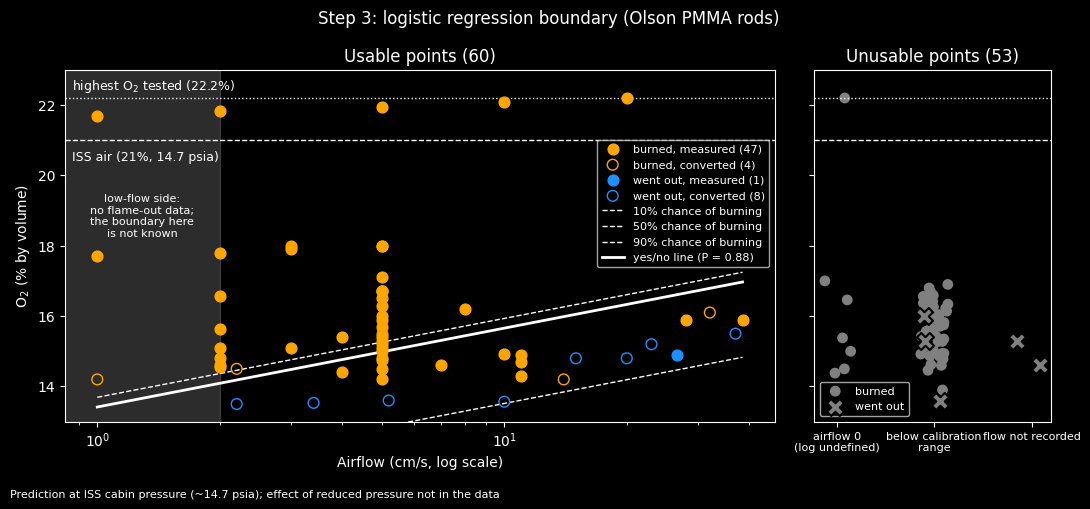

In [39]:
#-------------------------------------------------------------------------------
# O2 range of the plot
o2_bottom_zoom = 13
o2_top_zoom = 23
# airflow range to draw the boundary over (cm/s): the range of the usable data
airflow_min, airflow_max = data[airflow_column].min(), data[airflow_column].max()
# boundary line colour
boundary_colour = 'white'
#-------------------------------------------------------------------------------

# airflow values to draw the lines through, evenly spaced on the log scale
airflow_grid = np.geomspace(airflow_min, airflow_max, 200)

# draw the zoomed points plot
fig, ax = plot_points(data_all, o2_bottom_zoom, o2_top_zoom, 'Step 3: logistic regression boundary (Olson PMMA rods)')
# draw the dashed probability lines
for p in boundary_probabilities:
    ax.plot(airflow_grid, boundary_o2(airflow_grid, p, b0, b_o2, b_flow), color=boundary_colour,
            linestyle='--', linewidth=1, label=f'{int(p * 100)}% chance of burning')
# draw the solid yes/no line at the base-rate threshold
ax.plot(airflow_grid, boundary_o2(airflow_grid, threshold, b0, b_o2, b_flow), color=boundary_colour,
        linestyle='-', linewidth=2, label=f'yes/no line (P = {threshold:.2f})')
# grey out the low-flow side, where the boundary is not known
shade_unknown(ax)
# put the legend in the empty band between the data and the top lines, on the right
ax.legend(fontsize=8, loc='center right', bbox_to_anchor=(1, 0.62))
# caveat along the bottom of the figure
fig.text(0.01, 0.005, 'Prediction ' + prediction_caveat, fontsize=8, color='white')
# stop labels overlapping, leaving room for the caveat at the bottom
fig.tight_layout(rect=(0, 0.03, 1, 1))
# show the plot, then close it
plt.show()
plt.close()

**Finding:** The yes/no line rises from about 15.0% O₂ at 5 cm/s to 16.3% at 20 cm/s. The 10–90% probability band is wide (at 5 cm/s, roughly 10.4% to 15.3% O₂): with 9 flame-outs the transition is uncertain, not sharp. The grey region below 2 cm/s has no flame-out data, so the boundary there is unknown.

Here we:
- check how well the model fits **the points it was trained on**, using the yes/no threshold
- this is not a real test (the model has seen these points); Step 4's leave-one-test-out validation is the real test
- we count flame-outs and burns separately, because getting the rare flame-outs right is what matters

In [40]:
#-------------------------------------------------------------------------------
# the yes/no threshold from the base-rate cell
call_threshold = threshold
#-------------------------------------------------------------------------------

# predicted probability of burning for every usable point
p_burn = model.predict_proba(X)[:, 1]
# turn probabilities into burn / out calls
called_burn = (p_burn >= call_threshold).astype(int)

# how many real flame-outs the model called as flame-outs
outs_right = ((y == 0) & (called_burn == 0)).sum()
# how many real burns the model called as burns
burns_right = ((y == 1) & (called_burn == 1)).sum()

# print the counts
print(f"Flame-outs called correctly: {outs_right} of {(y == 0).sum()}")
print(f"Burns called correctly:      {burns_right} of {(y == 1).sum()}")

Flame-outs called correctly: 9 of 9
Burns called correctly:      37 of 51


**Finding:** On the data it was trained on, the model calls all 9 flame-outs correctly and 37 of 51 burns. The 14 missed burns are near-boundary points called as flame-outs: the cost of protecting the rare class with the base-rate threshold. This is training fit, not a real test (Step 4 is).

Here we:
- run the **sensitivity checks** from Step 2: refit the model on different versions of the data and see if the answer moves
  - all usable points (the main model)
  - without the black rods (O11, O14)
  - converted points at full weight instead of half
  - without converted points at all
- for each version, print the coefficients and the yes/no boundary O₂ (at that version's own base rate) at two airflows
- a version with very few flame-outs is flagged, because a model can't learn a boundary from one or two examples

In [41]:
#-------------------------------------------------------------------------------
# airflows (cm/s) at which to compare the yes/no boundary
compare_airflows = [5, 20]
# fewest flame-outs needed before a fit is worth reading
min_flameouts = 3
#-------------------------------------------------------------------------------

# the data versions to compare: name -> table of points
versions = {
    'all usable points': data,
    'without black rods': data[data['rod_colour'] != 'black'],
    'converted at full weight': data.assign(weight=1.0),
    'without converted points': data[data['airflow_source'] != 'converted'],
}

# empty list for the results
results = []
# go through each version
for name, d in versions.items():
    # build the inputs, answers and weights for this version
    Xv, yv, wv = make_xyw(d)
    # count the flame-outs in this version
    n_out = int((yv == 0).sum())
    # fit the model and get its coefficients in original units
    c0, c_o2, c_flow = original_units(fit_model(Xv, yv, wv))
    # this version's own yes/no threshold
    t_v = burn_base_rate(yv, wv)
    # store the summary row
    row = {'version': name, 'points': len(d), 'flame-outs': n_out,
           'b_o2': round(c_o2, 3), 'b_flow': round(c_flow, 3)}
    # add the yes/no boundary O2 (at this version's own base rate) at each comparison airflow
    for a in compare_airflows:
        row[f'yes/no O2 at {a} cm/s'] = round(boundary_o2(a, t_v, c0, c_o2, c_flow), 2)
    # flag versions with too few flame-outs
    row['warning'] = f'only {n_out} flame-out(s): unreliable' if n_out < min_flameouts else ''
    results.append(row)

# put the results in a table and print it
sensitivity = pd.DataFrame(results)
print(sensitivity.to_string(index=False))

                 version  points  flame-outs  b_o2  b_flow  yes/no O2 at 5 cm/s  yes/no O2 at 20 cm/s                         warning
       all usable points      60           9 0.909  -0.885                14.98                 16.33                                
      without black rods      57           8 0.861  -0.787                15.03                 16.30                                
converted at full weight      60           9 0.907  -1.098                14.79                 16.47                                
without converted points      48           1 0.176  -1.343                12.99                 23.56 only 1 flame-out(s): unreliable


**Finding:** The boundary barely moves without the black rods (≤0.05% O₂) or with converted points at full weight (≤0.2% O₂). But without converted points only 1 flame-out remains and no boundary can be learned: **the model depends on the fan-calibration conversion**.

Here we:
- draw the yes/no boundary of each reliable version on the zoomed plot, so we can see how much it moves
- versions flagged as unreliable are left off

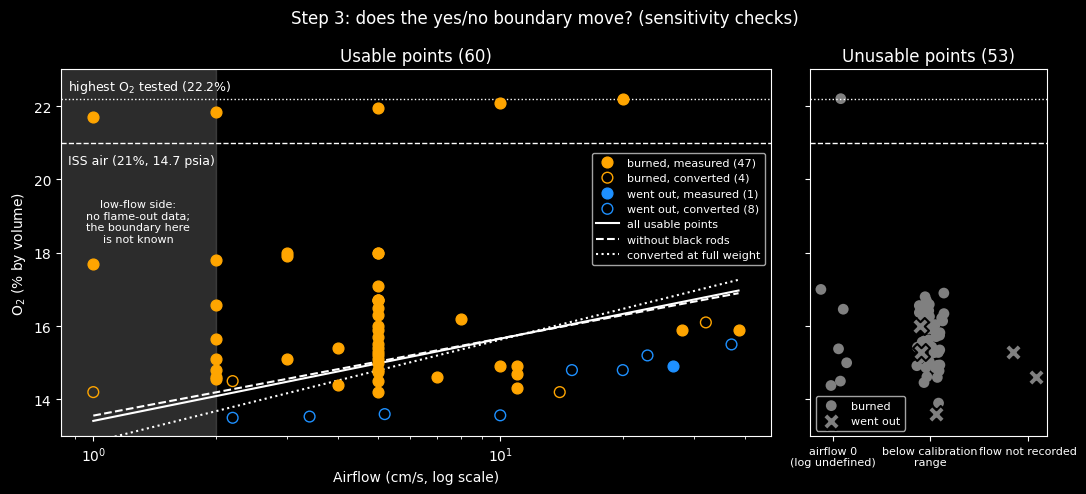

In [42]:
#-------------------------------------------------------------------------------
# line style for each version
version_styles = {'all usable points': '-', 'without black rods': '--',
                  'converted at full weight': ':', 'without converted points': '-.'}
#-------------------------------------------------------------------------------

# draw the zoomed points plot
fig, ax = plot_points(data_all, o2_bottom_zoom, o2_top_zoom, 'Step 3: does the yes/no boundary move? (sensitivity checks)')
# go through each version
for name, d in versions.items():
    # skip versions with too few flame-outs
    Xv, yv, wv = make_xyw(d)
    if (yv == 0).sum() < min_flameouts:
        continue
    # fit and get coefficients in original units
    c0, c_o2, c_flow = original_units(fit_model(Xv, yv, wv))
    # draw this version's yes/no boundary at its own base rate
    ax.plot(airflow_grid, boundary_o2(airflow_grid, burn_base_rate(yv, wv), c0, c_o2, c_flow), color=boundary_colour,
            linestyle=version_styles[name], linewidth=1.5, label=name)
# grey out the low-flow side, where the boundary is not known
shade_unknown(ax)
# put the legend in the empty band between the data and the top lines, on the right
ax.legend(fontsize=8, loc='center right', bbox_to_anchor=(1, 0.62))
# stop labels overlapping
fig.tight_layout()
# show the plot, then close it
plt.show()
plt.close()

**Finding:** The three reliable versions draw almost the same line, so the result isn't driven by the black rods or by how converted points are weighted.

---
# 12 Step 4: leave-one-test-out validation
---

Here we:
- test the model honestly: hide **one whole test** (all its points), train on every other test, then predict the hidden test's points
- repeat for every test, so every point gets predicted by a model that never saw its test
- why whole tests and not single points: points from the same test share a sample, a day and a stepped O₂, so hiding one point while its neighbours stay in training would flatter the model
- compare against the simplest rival, **"always predict burns"**, which is right 51 times out of 60 without learning anything
- expected weak spot: O12 holds 4 of the 9 flame-outs; with O12 hidden, training has no low-oxygen flame-outs left, so the model will probably miss O12. That is a data gap, not a bug

In [43]:
#-------------------------------------------------------------------------------
# yes/no rule: each fold's threshold is the burn base rate of ITS training data (the held-out test never influences it)
threshold_rule = 'training-fold weighted burn base rate'
#-------------------------------------------------------------------------------

# empty list to collect one row per predicted point
loto_rows = []
# go through each test in turn
for test in data['test_id'].unique():
    # training data: every point NOT from this test
    train = data[data['test_id'] != test]
    # held-out data: every point from this test
    held = data[data['test_id'] == test]
    # build inputs, answers and weights for both
    X_tr, y_tr, w_tr = make_xyw(train)
    X_te, y_te, _ = make_xyw(held)
    # fit the model on the training tests only
    m = fit_model(X_tr, y_tr, w_tr)
    # predicted probability of burning for the held-out points
    p = m.predict_proba(X_te)[:, 1]
    # this fold's yes/no threshold, from the training data only
    t_fold = burn_base_rate(y_tr, w_tr)
    # store one row per held-out point
    for i in range(len(held)):
        loto_rows.append({'test_id': test, 'o2_pct': held['o2_pct'].iloc[i],
                          'airflow_cm_s': held['airflow_cm_s'].iloc[i], 'burned': y_te[i],
                          'p_burn': p[i], 'threshold': t_fold, 'model_call': int(p[i] >= t_fold),
                          'baseline_call': 1,                                  # "always predict burns"
                          'train_flameouts': int((y_tr == 0).sum())})          # flame-outs left to learn from

# put the rows in a table
loto = pd.DataFrame(loto_rows)
# mark whether each call was right
loto['model_right'] = (loto['model_call'] == loto['burned']).astype(int)
loto['baseline_right'] = (loto['baseline_call'] == loto['burned']).astype(int)

# print how many points and tests were predicted
print(len(loto), "points predicted, from", loto['test_id'].nunique(), "held-out tests")

60 points predicted, from 26 held-out tests


Here we:
- summarise the results **per test**, so it's visible which tests the model gets wrong and why
- `train_flameouts` = how many flame-outs the model had to learn from when that test was hidden

In [44]:
#-------------------------------------------------------------------------------
# show only tests containing a flame-out or a model mistake (set False to show every test)
show_only_interesting = False
#-------------------------------------------------------------------------------

# one row per test: points, flame-outs, and how many each method got right
per_test = loto.groupby('test_id').agg(points=('burned', 'size'),
                                       flameouts=('burned', lambda b: int((b == 0).sum())),
                                       model_right=('model_right', 'sum'),
                                       baseline_right=('baseline_right', 'sum'),
                                       train_flameouts=('train_flameouts', 'first')).reset_index()
# optionally keep only the interesting tests
if show_only_interesting:
    per_test = per_test[(per_test['flameouts'] > 0) | (per_test['model_right'] < per_test['points'])]

# print the table
print(per_test.to_string(index=False))

test_id  points  flameouts  model_right  baseline_right  train_flameouts
     O1       5          0            5               5                9
    O10       3          0            2               3                9
    O11       2          1            2               1                8
    O12       4          4            1               0                5
   O13a       2          0            2               2                9
   O13b       2          0            0               2                9
    O14       1          0            1               1                9
   O15a       1          0            1               1                9
   O15b       1          0            1               1                9
    O16       1          0            0               1                9
    O17       2          0            1               2                9
    O18       6          0            4               6                9
    O19       1          0            1            

**Finding:** On unseen tests the model gets every blowoff test fully right (O7, O8b, O11, O22) where "always burns" gets half, and O9 half right. Its misses are near-boundary burns called as flame-outs (O13b, O16, O21, O5b, and 3 of 5 in O5a). O12 is only 1 of 4: with O12 hidden, only 5 flame-outs remain to learn from and none at low oxygen.

Here we:
- write a function that scores a set of predictions four ways:
  - **flame-outs caught**: of the real flame-outs, how many were called flame-out (the number that matters for safety)
  - **burns right**: of the real burns, how many were called burns
  - **balanced accuracy**: the average of those two rates, so the 51 burns can't drown out the 9 flame-outs
  - **Brier score**: the average squared gap between the predicted probability and what happened (0 = perfect, lower is better); it rewards being confident only when right. It uses the model's honest (unweighted) probabilities

In [45]:
#-------------------------------------------------------------------------------
# nothing to tweak: these are standard definitions
score_names = ['flame-outs caught', 'burns right', 'balanced accuracy', 'Brier score']
#-------------------------------------------------------------------------------

def score(burned, call, p_burn):
    # masks for the real flame-outs and the real burns
    outs, burns = (burned == 0), (burned == 1)
    # fraction of real flame-outs called flame-out
    out_rate = (call[outs] == 0).mean() if outs.any() else np.nan
    # fraction of real burns called burns
    burn_rate = (call[burns] == 1).mean() if burns.any() else np.nan
    # balanced accuracy: average of the two rates
    balanced = np.nanmean([out_rate, burn_rate])
    # Brier score: mean squared gap between probability and outcome
    brier = np.mean((p_burn - burned) ** 2)
    # hand back all four, with the raw counts for the first two
    return {'flame-outs caught': f"{int((call[outs] == 0).sum())}/{int(outs.sum())}",
            'burns right': f"{int((call[burns] == 1).sum())}/{int(burns.sum())}",
            'balanced accuracy': round(balanced, 3), 'Brier score': round(brier, 3)}

# confirm the function is ready
print("score() defined")

score() defined


Here we:
- score the model and the "always burns" baseline on all held-out points
- then again **without O12**, so we can see how much of the result is that one test
- the baseline's probability is 1.0 for every point (it is certain everything burns)

In [46]:
#-------------------------------------------------------------------------------
# test to leave out in the second comparison
test_to_drop = 'O12'
#-------------------------------------------------------------------------------

# empty list for the summary rows
summary = []
# two versions of the held-out predictions: everything, and without the chosen test
for label, d in [('all tests', loto), (f'without {test_to_drop}', loto[loto['test_id'] != test_to_drop])]:
    # score the model
    summary.append({'data': label, 'method': 'model',
                    **score(d['burned'].to_numpy(), d['model_call'].to_numpy(), d['p_burn'].to_numpy())})
    # score the baseline (always burns, probability 1.0)
    summary.append({'data': label, 'method': 'always burns',
                    **score(d['burned'].to_numpy(), d['baseline_call'].to_numpy(), np.ones(len(d)))})

# print the comparison table
print(pd.DataFrame(summary).to_string(index=False))
# remind the reader of the pressure caveat
print("\nAll predictions:", prediction_caveat)

       data       method flame-outs caught burns right  balanced accuracy  Brier score
  all tests        model               6/9       36/51              0.686        0.120
  all tests always burns               0/9       51/51              0.500        0.150
without O12        model               5/5       36/51              0.853        0.065
without O12 always burns               0/5       51/51              0.500        0.089

All predictions: at ISS cabin pressure (~14.7 psia); effect of reduced pressure not in the data


**Finding:** On held-out tests the model catches 6 of 9 flame-outs (the baseline catches none). Balanced accuracy 0.69 vs 0.50, Brier score 0.120 vs 0.150 for "always burns". Without O12 it catches all 5 flame-outs (balanced accuracy 0.85, Brier 0.065 vs 0.089). The weak spot is low-oxygen flame-outs, because one test holds all of them.

Here we:
- list every flame-out point with the probability of burning the model gave it when its test was hidden
- this shows which flame-outs the model sees coming and which surprise it

In [47]:
#-------------------------------------------------------------------------------
# columns to show
columns_to_show = ['test_id', 'o2_pct', 'airflow_cm_s', 'p_burn', 'threshold', 'model_call', 'train_flameouts']
#-------------------------------------------------------------------------------

# pick the real flame-outs and print them, lowest probability of burning first
print(loto.loc[loto['burned'] == 0, columns_to_show].sort_values('p_burn').round(3).to_string(index=False))

test_id  o2_pct  airflow_cm_s  p_burn  threshold  model_call  train_flameouts
    O11  14.800          20.0   0.665      0.881           0                8
    O22  14.900          26.5   0.687      0.889           0                8
     O7  15.500          37.0   0.711      0.881           0                8
     O9  14.800          15.0   0.712      0.881           0                8
    O8b  15.200          23.0   0.722      0.881           0                8
    O12  13.567          10.0   0.871      0.942           0                5
    O12  13.600           5.2   0.951      0.942           1                5
    O12  13.533           3.4   0.974      0.942           1                5
    O12  13.500           2.2   0.987      0.942           1                5


**Finding:** The model sees every blowoff coming (P(burn) 0.67–0.72, below the ~0.88 threshold) without having seen that test. It doesn't see O12's low-oxygen failures (P(burn) 0.87–0.99): with O12 hidden, there are no low-O₂ flame-outs left to learn from.

Here we:
- draw one bar per test: the fraction of its points each method got right
- **all** tests are shown, not just the ones with flame-outs, so the model's false alarms (burns it called flame-outs) are visible too
- tests with a flame-out come first; white = model, grey = always burns

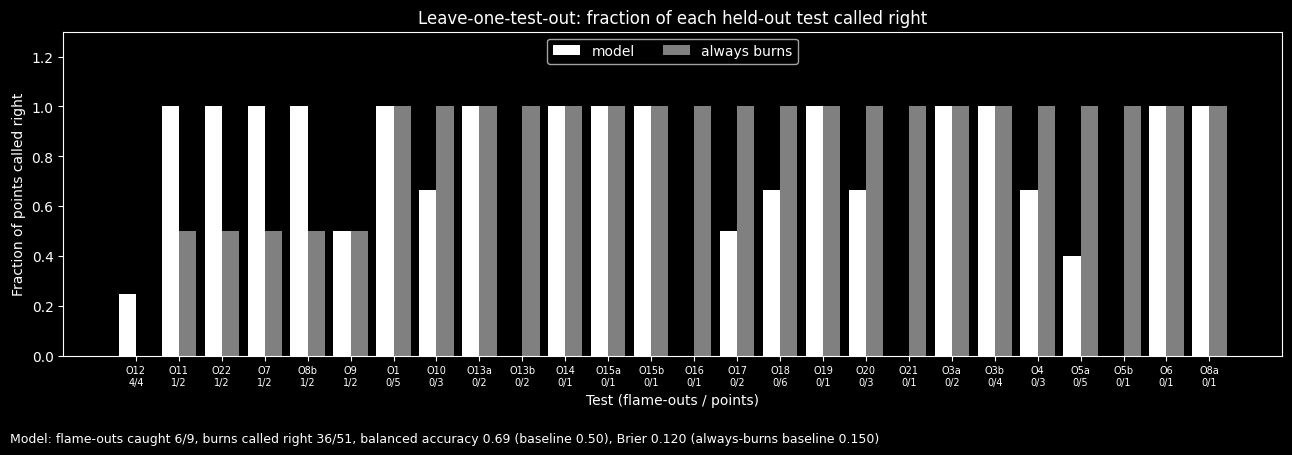

Model: flame-outs caught 6/9, burns called right 36/51, balanced accuracy 0.69 (baseline 0.50), Brier 0.120 (always-burns baseline 0.150)


In [48]:
#-------------------------------------------------------------------------------
# bar colours
model_colour = 'white'
baseline_colour = 'grey'
# bar width
bar_width = 0.4
#-------------------------------------------------------------------------------

# every test, the ones with flame-outs first, then by name
t = per_test.sort_values(['flameouts', 'test_id'], ascending=[False, True]).reset_index(drop=True)
# positions of the bars along the x axis
x = np.arange(len(t))

# make a figure
fig, ax = plt.subplots(figsize=(13, 4.5))
# model bars, shifted left
ax.bar(x - bar_width / 2, t['model_right'] / t['points'], bar_width, color=model_colour, label='model')
# baseline bars, shifted right
ax.bar(x + bar_width / 2, t['baseline_right'] / t['points'], bar_width, color=baseline_colour, label='always burns')
# test names under the bars, with the number of flame-outs
ax.set_xticks(x)
ax.set_xticklabels([f"{r.test_id}\n{r.flameouts}/{r.points}" for r in t.itertuples()], fontsize=7)
# explain the numbers under the test names
ax.set_xlabel('Test (flame-outs / points)')
# axis labels, title and legend
ax.set_ylabel('Fraction of points called right')
ax.set_ylim(0, 1.3)
ax.set_title('Leave-one-test-out: fraction of each held-out test called right')
ax.legend(loc='upper center', ncol=2)
# score the model and the baseline on all held-out points
m_s = score(loto['burned'].to_numpy(), loto['model_call'].to_numpy(), loto['p_burn'].to_numpy())
b_s = score(loto['burned'].to_numpy(), loto['baseline_call'].to_numpy(), np.ones(len(loto)))
# one summary line under the chart
summary_line = (f"Model: flame-outs caught {m_s['flame-outs caught']}, burns called right {m_s['burns right']}, "
                f"balanced accuracy {m_s['balanced accuracy']:.2f} (baseline 0.50), "
                f"Brier {m_s['Brier score']:.3f} (always-burns baseline {b_s['Brier score']:.3f})")
fig.text(0.01, 0.005, summary_line, fontsize=9, color='white')
# stop labels overlapping, leaving room for the summary line
fig.tight_layout(rect=(0, 0.05, 1, 1))
# show the plot, then close it
plt.show()
plt.close()
# print the same line, so it can be copied
print(summary_line)

**Finding:** Unseen tests: the model beats "always burns" on every test with a flame-out except O12, and loses on some all-burn tests near the boundary. Overall it is better than the baseline (balanced accuracy 0.69 vs 0.50, Brier 0.120 vs 0.150) but not a precise predictor yet: more flame-out data, especially at low oxygen and low flow, would help most.

---
# 13 Step 5: choose the next experiment (trust region)
---

How `next_experiment()` works:
1. **Trust region**: tests may only go a limited step beyond what has been tested: up to 3 percentage points of O₂ **above** the highest tested O₂ (never below the lowest tested O₂, 13.5%: the region only grows towards the habitat set-points), and a factor of 3 in airflow past the tested range. The size is set by a **radius** (1 to start, capped at 3); in Step 6 it grows ×1.5 after a right prediction and shrinks ×0.5 after a wrong one
2. **Airflow limits** for recommended tests: 2–30 cm/s. Below 2 cm/s the boundary is not known (Step 3); 30 cm/s is the top of SoFIE's planned flow range (NASA's Researcher's Guide to Combustion Science). Faster flows are not a habitat fire risk
3. **Score** inside the region = **disagreement** × **Moon relevance**
   - disagreement: the spread of P(burn) across ~100 models, each fitted to data resampled by test (a bootstrap). Where they disagree, a test teaches us something
   - Moon relevance = O₂ relevance × airflow relevance:
     - O₂: a ramp that rises steadily from the lowest tested O₂ (13.5%) up to 34%, NASA's main habitat set-point
     - airflow: full weight inside the crew-cabin ventilation band, 7.6–20.3 cm/s (15–40 ft/min, the Space Station cabin air-velocity requirement), fading outside it
4. There is **no distance reward**: the trust region already decides how far we may extrapolate, so the method walks towards 34% one step at a time instead of jumping there
5. Every recommended test is at ISS cabin pressure (14.7 psia) on the ISS: the only pressure in the data. The pressure question is handled separately, as a "frontier" pair (end of this section)

Here we:
- set where recommended tests run and the starting trust-region size
- write `trust_region()`: from the tested data and a radius, work out the O₂ and airflow limits
- the region is **one-sided in O₂**: it reaches 3 points above the highest tested O₂, but never below the lowest O₂ NASA tested (13.5%)
- write `in_region()`: mark which points fall inside those limits
- the 2–30 cm/s airflow limits apply to new tests we recommend; NASA's own tests in the Step 6 pool (1 to 38.5 cm/s) are checked without them
- the radius is capped at 3× its starting size, so the region can never cover the whole space

In [49]:
#-------------------------------------------------------------------------------
# where recommended tests run; SoFIE limits from NASA's Researcher's Guide to Combustion Science (0.2-1.5 atm, 10-40% O2)
platform_name = 'ISS (SoFIE, Combustion Integrated Rack)'
# pressure of every recommended test (psia): ISS cabin, the only pressure in the data
test_pressure_psia = 14.7
# starting trust region: O2 margin (percentage points) and airflow factor beyond the tested range
o2_margin_start = 3.0
airflow_factor_start = 3.0
# lowest O2 any test may have: the lowest O2 NASA tested (the region only grows upwards)
o2_floor = data['o2_pct'].min()
# starting radius (1 = the margins above), and the largest it may grow to
radius_start = 1.0
radius_cap = 3.0 * radius_start
# airflow limits for recommended tests (cm/s): the no-data floor, and the top of SoFIE's planned range
flow_min_recommend = no_data_below_cm_s
flow_max_recommend = 30.0
#-------------------------------------------------------------------------------

def trust_region(d, radius):
    # O2 margin grows in proportion to the radius
    o2_margin = o2_margin_start * radius
    # airflow factor grows as a power of the radius (radius 2 -> 3 x 3 = 9 times)
    flow_factor = airflow_factor_start ** radius
    # the limits: tested range widened by the margins; O2 only upwards (the lower limit is fixed at o2_floor)
    # flow_low / flow_high: clipped to 2-30 cm/s (for new tests we recommend)
    # flow_low_pool / flow_high_pool: not clipped (Step 6, where the pool is NASA's own tests, from 1 to 38.5 cm/s)
    return {'o2_low': o2_floor,
            'o2_high': d['o2_pct'].max() + o2_margin,
            'flow_low': max(flow_min_recommend, d['airflow_cm_s'].min() / flow_factor),
            'flow_high': min(flow_max_recommend, d['airflow_cm_s'].max() * flow_factor),
            'flow_low_pool': d['airflow_cm_s'].min() / flow_factor,
            'flow_high_pool': d['airflow_cm_s'].max() * flow_factor}

def in_region(points, region, pool=False):
    # airflow limits: clipped to 2-30 cm/s for new tests, unclipped for NASA's own tests (pool=True)
    flow_low = region['flow_low_pool'] if pool else region['flow_low']
    flow_high = region['flow_high_pool'] if pool else region['flow_high']
    # True where a point's O2 and airflow are both inside the limits
    return ((points['o2_pct'] >= region['o2_low']) & (points['o2_pct'] <= region['o2_high'])
            & (points['airflow_cm_s'] >= flow_low) & (points['airflow_cm_s'] <= flow_high))

# print the starting trust region for all usable points
print({k: round(v, 2) for k, v in trust_region(data, radius_start).items()})

{'o2_low': 13.5, 'o2_high': 25.2, 'flow_low': 2.0, 'flow_high': 30.0, 'flow_low_pool': 0.33, 'flow_high_pool': 115.5}


Here we:
- write `candidate_grid()`: every test we could run inside a trust region, on a grid of O₂ (0.5% steps) × airflow (evenly spaced on the log scale)

In [50]:
#-------------------------------------------------------------------------------
# O2 step of the grid (% by volume)
o2_grid_step = 0.5
# number of airflow values
n_airflows = 25
#-------------------------------------------------------------------------------

def candidate_grid(region):
    # O2 values from the region's lower to upper limit, on whole 0.5% steps
    o2_values = np.arange(np.ceil(region['o2_low'] / o2_grid_step) * o2_grid_step,
                          region['o2_high'] + 1e-9, o2_grid_step)
    # airflow values from the region's lower to upper limit, evenly spaced on the log scale
    airflows = np.geomspace(region['flow_low'], region['flow_high'], n_airflows)
    # every combination, as a table
    return pd.DataFrame([(o, a) for o in o2_values for a in airflows], columns=['o2_pct', 'airflow_cm_s'])

# build the starting grid and print its size
print(len(candidate_grid(trust_region(data, radius_start))), "candidate tests in the starting trust region")

600 candidate tests in the starting trust region


Here we:
- write the **bootstrap**: make many slightly different versions of the data and fit a model to each
- whole **tests** are resampled, not single points (points from one test belong together, as in Step 4)
- a resample must contain flame-outs (3, or all there are if the data has fewer) and burns, otherwise it can't define a boundary and is drawn again
- each model is the honest one (no class weighting)

In [51]:
#-------------------------------------------------------------------------------
# fewest flame-outs a resample must contain (lowered automatically if the data has fewer)
min_flameouts_boot = 3
#-------------------------------------------------------------------------------

def bootstrap_models(d, n_models, rng):
    # list of the test IDs
    tests = d['test_id'].unique()
    # row positions of each test's points (so a resample is a fast lookup, not a table rebuild)
    rows_of = {t: np.flatnonzero(d['test_id'].to_numpy() == t) for t in tests}
    # flame-outs required: 3, or all of them if the data has fewer
    need_outs = min(min_flameouts_boot, int((d['burned'] == 0).sum()))
    # empty list for the fitted models
    models = []
    # keep going until we have enough models
    while len(models) < n_models:
        # draw as many tests as there are, with replacement
        picked = rng.choice(tests, size=len(tests), replace=True)
        # the points of the picked tests (a test picked twice appears twice)
        sample = d.iloc[np.concatenate([rows_of[t] for t in picked])]
        # build inputs, answers and weights
        Xb, yb, wb = make_xyw(sample)
        # skip resamples without enough flame-outs, or without any burns
        if (yb == 0).sum() < need_outs or (yb == 1).sum() == 0:
            continue
        # fit and keep the model
        models.append(fit_model(Xb, yb, wb))
    # hand back the list of models
    return models

# confirm the function is ready
print("bootstrap_models() defined")

bootstrap_models() defined


Here we:
- write `score_points()`: for any table of points (grid candidates, or NASA's tests in Step 6):
  - **P(burn)** from every bootstrap model → mean, and the 5th–95th percentile = the **90% range**
  - **disagreement** = spread (standard deviation) of P(burn) across the models
  - **relevance** = O₂ relevance × airflow relevance
    - O₂: a ramp: the floor at the lowest tested O₂ (13.5%), rising in a straight line to 1 at 34%, NASA's main habitat set-point
    - airflow: 1 inside the cabin ventilation band (7.6–20.3 cm/s); outside it, a floor plus a bump that fades with the factor away from the band
  - **score** = disagreement × relevance

In [52]:
#-------------------------------------------------------------------------------
# O2 at which the relevance ramp reaches 1 (NASA's main habitat set-point)
ramp_top_o2 = 34.0
# relevance at the bottom of the ramp, and the lowest any point can have
relevance_floor = 0.2
# crew-cabin ventilation band (cm/s): 15-40 ft/min, the Space Station cabin air-velocity requirement
cabin_flow_band = (7.6, 20.3)
# how fast airflow relevance fades outside the band: one width = this factor away from the band edge
flow_width_factor = 2.0
#-------------------------------------------------------------------------------

def score_points(points, models):
    # inputs in the model's form: O2 and log(airflow)
    Xc = np.column_stack([points['o2_pct'], np.log(points['airflow_cm_s'])])
    # P(burn) for every model (rows) and point (columns)
    P = np.array([m.predict_proba(Xc)[:, 1] for m in models])
    # copy the table so the original isn't changed
    out = points.copy()
    # mean prediction and 90% range across the models
    out['p_burn'] = P.mean(axis=0)
    out['p_low_5'] = np.percentile(P, 5, axis=0)
    out['p_high_95'] = np.percentile(P, 95, axis=0)
    # disagreement: spread of P(burn) across the models
    out['disagreement'] = P.std(axis=0)
    # how far up the ramp each point is: 0 at the lowest tested O2, 1 at the top (clipped to 0-1)
    ramp = np.clip((out['o2_pct'] - o2_floor) / (ramp_top_o2 - o2_floor), 0, 1)
    # O2 relevance: rises in a straight line from the floor to 1
    out['o2_relevance'] = relevance_floor + (1 - relevance_floor) * ramp
    # how many 'widths' (on the log scale) each airflow is outside the cabin band (0 inside it)
    lo, hi = cabin_flow_band
    outside = np.maximum(np.log(lo / out['airflow_cm_s']), 0) + np.maximum(np.log(out['airflow_cm_s'] / hi), 0)
    widths = outside / np.log(flow_width_factor)
    # airflow relevance: 1 inside the band, fading to the floor outside it
    out['flow_relevance'] = relevance_floor + (1 - relevance_floor) * np.exp(-0.5 * widths ** 2)
    # overall relevance
    out['relevance'] = out['o2_relevance'] * out['flow_relevance']
    # final score
    out['score'] = out['disagreement'] * out['relevance']
    # hand back the scored table
    return out

# confirm the function is ready
print("score_points() defined")

score_points() defined


Here we:
- write `next_experiment()`: fit the bootstrap models, score every candidate inside the trust region, and return the best one:
  - O₂ %, airflow, pressure (14.7 psia), platform (ISS)
  - P(burn) with its 90% range from the bootstrap, and the yes/no call (flame-out if P(burn) is below the burn base rate)
  - the score, the radius used, and the prediction caveat

In [53]:
#-------------------------------------------------------------------------------
# number of bootstrap models
n_models = 100
#-------------------------------------------------------------------------------

def next_experiment(d, rng, radius=radius_start, return_table=False):
    # fit the bootstrap models on the current data
    models = bootstrap_models(d, n_models, rng)
    # the trust region around the current data
    region = trust_region(d, radius)
    # score every candidate inside it, best first
    scored = score_points(candidate_grid(region), models).sort_values('score', ascending=False).reset_index(drop=True)
    # the winning candidate
    best = scored.iloc[0]
    # yes/no threshold from the current data
    Xd, yd, wd = make_xyw(d)
    t = burn_base_rate(yd, wd)
    # the plain answer
    answer = {'track': 'Refine', 'o2_pct': float(best['o2_pct']), 'airflow_cm_s': round(float(best['airflow_cm_s']), 2),
              'pressure_psia': test_pressure_psia, 'platform': platform_name,
              'p_burn': round(float(best['p_burn']), 3),
              'p_burn_90pct_range': (round(float(best['p_low_5']), 3), round(float(best['p_high_95']), 3)),
              'call': 'burns' if best['p_burn'] >= t else 'flame-out',
              'score': round(float(best['score']), 4), 'trust_radius': radius, 'caveat': prediction_caveat}
    # optionally also hand back the scored table and the region (for plots)
    return (answer, scored, region) if return_table else answer

# confirm the function is ready
print("next_experiment() defined")

next_experiment() defined


Here we:
- run `next_experiment()` on all 60 usable points with the starting radius, and print its recommendation
- the random generator uses the notebook seed, so the answer is the same every run

In [54]:
#-------------------------------------------------------------------------------
# trust radius for today's recommendation
radius_today = radius_start
#-------------------------------------------------------------------------------

# random generator for the bootstrap, seeded so results repeat
rng = np.random.default_rng(seed)
# ask for the next experiment, keeping the scored table and region for the plot
answer, scored, region = next_experiment(data, rng, radius_today, return_table=True)

# print each part of the answer on its own line
for key, value in answer.items():
    print(f"{key:>20}: {value}")

               track: Refine
              o2_pct: 13.5
        airflow_cm_s: 8.67
       pressure_psia: 14.7
            platform: ISS (SoFIE, Combustion Integrated Rack)
              p_burn: 0.53
  p_burn_90pct_range: (0.159, 0.936)
                call: flame-out
               score: 0.0538
        trust_radius: 1.0
              caveat: at ISS cabin pressure (~14.7 psia); effect of reduced pressure not in the data


**Finding:** Refine recommends **13.5% O₂ at 8.7 cm/s** (inside the cabin ventilation band), where P(burn) = 0.53 with a 90% range of 0.16–0.94: a coin flip on the oxygen limit, so whatever happens, NASA learns the most there.

Here we:
- print the top 10 candidates, to see what came close and why

In [55]:
#-------------------------------------------------------------------------------
# how many candidates to show
n_show = 10
# columns to show
columns_to_show = ['o2_pct', 'airflow_cm_s', 'p_burn', 'p_low_5', 'p_high_95', 'disagreement',
                   'o2_relevance', 'flow_relevance', 'score']
#-------------------------------------------------------------------------------

# print the best candidates
print(scored[columns_to_show].head(n_show).round(3).to_string(index=False))

 o2_pct  airflow_cm_s  p_burn  p_low_5  p_high_95  disagreement  o2_relevance  flow_relevance  score
   13.5         8.671   0.530    0.159      0.936         0.269           0.2           1.000  0.054
   13.5         7.746   0.549    0.174      0.945         0.269           0.2           1.000  0.054
   13.5         9.707   0.510    0.144      0.923         0.268           0.2           1.000  0.054
   13.5        10.866   0.489    0.131      0.908         0.266           0.2           1.000  0.053
   13.5         6.919   0.568    0.194      0.953         0.267           0.2           0.993  0.053
   13.5        12.164   0.468    0.119      0.891         0.262           0.2           1.000  0.052
   13.5        13.617   0.447    0.107      0.870         0.258           0.2           1.000  0.052
   13.5         6.181   0.587    0.211      0.959         0.265           0.2           0.965  0.051
   13.5        15.244   0.426    0.091      0.847         0.252           0.2           1.0

**Finding:** All the top candidates sit at 13.5% O₂ across the ventilation band (6–17 cm/s), where disagreement is ~0.25–0.27. Inside the data, the models disagree most at the low-oxygen limit, so that is where a test teaches the most.

**Two tracks: Refine and Explore**

The method gives two recommendations, because one score can't do both jobs:

- **Track 1, Refine** (`next_experiment()`): the test inside the trust region where the bootstrap models **disagree most**, weighted by Moon relevance (O₂ ramp × cabin airflow band). This sharpens the boundary we already have evidence about. It is the part the Step 6 replay validates on NASA's real tests
- **Track 2, Explore** (`explore_experiment()`): a test at the **top O₂ edge** of the trust region, with the airflow inside the cabin ventilation band where the models disagree most at that O₂. This takes the next step towards the habitat set-points. Above 22% O₂ every model extends the same straight line, so disagreement can't see the risk there; Explore steps up anyway, by a fixed, limited amount (the trust region), instead of jumping straight to 34%
- **Frontier pressure pair**: 34% O₂ at 8.2 and 14.7 psia, the first data on the pressure effect, which the model cannot predict at all

The replay (Step 6) only checks Refine, because NASA's tests never went above 22% O₂.

Here we:
- write `explore_experiment()`: the **Explore** track
  - O₂ = the top edge of the trust region (highest tested O₂ + the O₂ margin)
  - airflow = the value inside the cabin ventilation band (7.6–20.3 cm/s) where the bootstrap models disagree most at that O₂
- it returns the same kind of answer as `next_experiment()`, plus a note on how far above the tested data it is

In [56]:
#-------------------------------------------------------------------------------
# number of airflow values to try inside the cabin ventilation band
n_band_airflows = 25
#-------------------------------------------------------------------------------

def explore_experiment(d, rng, radius=radius_start):
    # fit the bootstrap models on the current data
    models = bootstrap_models(d, n_models, rng)
    # the trust region around the current data
    region = trust_region(d, radius)
    # O2 at the top edge of the region
    o2_top = region['o2_high']
    # airflow values inside the cabin ventilation band (and inside the region's airflow limits)
    lo, hi = max(cabin_flow_band[0], region['flow_low']), min(cabin_flow_band[1], region['flow_high'])
    band_airflows = np.geomspace(lo, hi, n_band_airflows)
    # score each airflow at the top O2
    pts_top = pd.DataFrame({'o2_pct': o2_top, 'airflow_cm_s': band_airflows})
    scored_top = score_points(pts_top, models)
    # the airflow with the most disagreement
    best = scored_top.loc[scored_top['disagreement'].idxmax()]
    # yes/no threshold from the current data
    Xd, yd, wd = make_xyw(d)
    t = burn_base_rate(yd, wd)
    # how far above the highest tested O2 this is
    above = o2_top - d['o2_pct'].max()
    # the plain answer
    return {'track': 'Explore', 'o2_pct': round(float(o2_top), 2), 'airflow_cm_s': round(float(best['airflow_cm_s']), 2),
            'pressure_psia': test_pressure_psia, 'platform': platform_name,
            'p_burn': round(float(best['p_burn']), 3),
            'p_burn_90pct_range': (round(float(best['p_low_5']), 3), round(float(best['p_high_95']), 3)),
            'call': 'burns' if best['p_burn'] >= t else 'flame-out',
            'disagreement': round(float(best['disagreement']), 4), 'trust_radius': radius,
            'note': (f"{above:.1f} percentage points of O2 above the highest tested; the 90% range can't show "
                     "extrapolation uncertainty (every model extends the same straight line)"),
            'caveat': prediction_caveat}

# confirm the function is ready
print("explore_experiment() defined")

explore_experiment() defined


Here we:
- run `explore_experiment()` on all 60 usable points with the starting radius, and print its recommendation

In [57]:
#-------------------------------------------------------------------------------
# trust radius for today's Explore recommendation
radius_today_explore = radius_start
#-------------------------------------------------------------------------------

# ask for the Explore test (seeded, so it repeats)
explore = explore_experiment(data, np.random.default_rng(seed), radius_today_explore)

# print each part of the answer on its own line
for key, value in explore.items():
    print(f"{key:>20}: {value}")

               track: Explore
              o2_pct: 25.2
        airflow_cm_s: 20.3
       pressure_psia: 14.7
            platform: ISS (SoFIE, Combustion Integrated Rack)
              p_burn: 0.995
  p_burn_90pct_range: (0.979, 1.0)
                call: burns
        disagreement: 0.01
        trust_radius: 1.0
                note: 3.0 percentage points of O2 above the highest tested; the 90% range can't show extrapolation uncertainty (every model extends the same straight line)
              caveat: at ISS cabin pressure (~14.7 psia); effect of reduced pressure not in the data


**Finding:** Explore recommends **25.2% O₂ at 20.3 cm/s**, 3 points above the highest O₂ tested, inside the trust region. The model says it burns (P = 0.995), but every model extends the same straight line, so this range can't show the real extrapolation uncertainty. That is exactly why it is worth testing.

Here we:
- draw the trust region (dashed white outline), the Refine score inside it (colour), the tested points (orange burned, blue went out), the Refine test (white star) and the Explore test (white diamond)
- the low-flow side below 2 cm/s stays greyed out

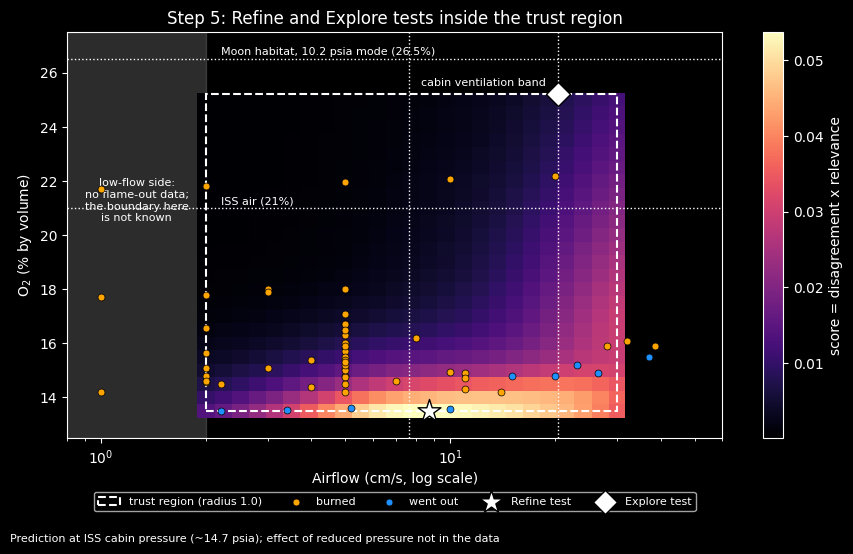

In [58]:
#-------------------------------------------------------------------------------
# colour map for the score
map_colours = 'magma'
# O2 range of the plot: from just below the trust region (or 13%, whichever is lower)
o2_bottom_plot = min(13, region['o2_low']) - 0.5
# reference lines to show if they fall in range: (O2 %, label)
plot_lines = [(21.0, 'ISS air (21%)'), (26.5, 'Moon habitat, 10.2 psia mode (26.5%)')]
#-------------------------------------------------------------------------------

# import the rectangle shape for the trust-region outline
from matplotlib.patches import Rectangle

# reshape the scores into an O2 x airflow table
table = scored.pivot(index='o2_pct', columns='airflow_cm_s', values='score')
# make a figure
fig, ax = plt.subplots(figsize=(9, 5.5))
# draw the score inside the trust region as a coloured grid
mesh = ax.pcolormesh(table.columns, table.index, table.values, cmap=map_colours, shading='auto', zorder=1)
# colour bar
fig.colorbar(mesh, ax=ax, label='score = disagreement x relevance')
# trust-region outline
ax.add_patch(Rectangle((region['flow_low'], region['o2_low']), region['flow_high'] - region['flow_low'],
                       region['o2_high'] - region['o2_low'], fill=False, edgecolor='white', linestyle='--',
                       linewidth=1.5, zorder=3, label=f'trust region (radius {radius_today})'))
# tested points: orange burned, blue went out
for b, colour, label in [(1, burned_colour, 'burned'), (0, out_colour, 'went out')]:
    g = data[data['burned'] == b]
    ax.scatter(g['airflow_cm_s'], g['o2_pct'], s=25, color=colour, edgecolors='black', linewidths=0.5, zorder=4, label=label)
# the Refine test as a white star, the Explore test as a white diamond
ax.scatter(answer['airflow_cm_s'], answer['o2_pct'], s=300, marker='*', color='white', edgecolors='black',
           zorder=5, label='Refine test')
ax.scatter(explore['airflow_cm_s'], explore['o2_pct'], s=150, marker='D', color='white', edgecolors='black',
           zorder=5, label='Explore test')
# axis ranges: a little beyond the trust region
o2_top_plot = max(region['o2_high'], 26.5) + 1
ax.set_xscale('log')
ax.set_xlim(0.8, 60)
ax.set_ylim(o2_bottom_plot, o2_top_plot)
# reference lines inside the plotted range
for level, label in plot_lines:
    if level <= o2_top_plot:
        ax.axhline(level, color='white', linestyle=':', linewidth=1)
        ax.text(region['flow_low'] * 1.1, level + 0.15, label, color='white', fontsize=8)
# mark the crew-cabin ventilation band
for edge in cabin_flow_band:
    ax.axvline(edge, color='white', linestyle=':', linewidth=1)
ax.text(np.sqrt(cabin_flow_band[0] * cabin_flow_band[1]), region['o2_high'] + 0.3, 'cabin ventilation band',
        color='white', fontsize=8, ha='center')
# grey out the low-flow side
shade_unknown(ax)
# labels, title, legend and caveat
ax.set_xlabel('Airflow (cm/s, log scale)')
ax.set_ylabel('O$_2$ (% by volume)')
ax.set_title('Step 5: Refine and Explore tests inside the trust region')
ax.legend(fontsize=8, loc='upper center', bbox_to_anchor=(0.5, -0.12), ncol=5)
fig.text(0.01, 0.005, 'Prediction ' + prediction_caveat, fontsize=8, color='white')
# stop labels overlapping
fig.tight_layout(rect=(0, 0.03, 1, 1))
# show the plot, then close it
plt.show()
plt.close()

**Finding:** Inside the trust region, disagreement is concentrated at low oxygen (Refine, star). Explore (diamond) steps up to the top edge of the region, towards the 26.5% habitat set-point. The method walks towards Moon air in limited steps instead of jumping to 34%.

Here we:
- print the **frontier pressure pair**: the same test at 34% O₂ at 8.2 psia and at 14.7 psia
- the model can only give a number for the 14.7 psia version (and that is far outside the data); it cannot predict the 8.2 psia version at all
- the airflow is the one BASS-II used most often, taken from the data

In [59]:
#-------------------------------------------------------------------------------
# O2 of the frontier pair (NASA's main habitat set-point)
frontier_o2 = 34.0
# the two pressures (psia): habitat set-point and ISS cabin
frontier_pressures = [8.2, 14.7]
# label for the pair
frontier_label = ("first data: the model can't predict the pressure effect; separates oxygen-fraction and pressure "
                  "effects; within the planned SoFIE ISS hardware range (0.2-1.5 atm, 10-40% O2, "
                  "per NASA's Researcher's Guide to Combustion Science)")
#-------------------------------------------------------------------------------

# the airflow BASS-II used most often (the most common value in the usable data)
frontier_airflow = float(data['airflow_cm_s'].mode()[0])
# bootstrap models on all usable data (seeded)
frontier_models = bootstrap_models(data, n_models, np.random.default_rng(seed))
# score the 14.7 psia version (the only one the model can see)
frontier_score = score_points(pd.DataFrame({'o2_pct': [frontier_o2], 'airflow_cm_s': [frontier_airflow]}), frontier_models).iloc[0]

# one row per pressure
frontier = pd.DataFrame([
    {'o2_pct': frontier_o2, 'airflow_cm_s': frontier_airflow, 'pressure_psia': p, 'platform': platform_name,
     'p_burn': round(float(frontier_score['p_burn']), 3) if p == test_pressure_psia else 'no prediction (pressure not in the data)',
     'p_burn_90pct_range': (round(float(frontier_score['p_low_5']), 3), round(float(frontier_score['p_high_95']), 3)) if p == test_pressure_psia else '',
     'note': frontier_label}
    for p in frontier_pressures])

# evidence for the airflow choice: how many tests started (first point) at this airflow
first_points = data_all[data_all['point_order'] == 0]
n_start_here = int((first_points['airflow_cm_s'] == frontier_airflow).sum())
print(f"Frontier airflow {frontier_airflow:g} cm/s: the most common airflow in the usable data, and the first "
      f"airflow of {n_start_here} of {len(first_points)} Olson tests (the standard BASS-II ignition flow)\n")
# print the pair (without the long note), then the note once
print(frontier.drop(columns='note').to_string(index=False))
print("\nLabel:", frontier_label)
print(f"\nThe 14.7 psia number is {frontier_o2 - data['o2_pct'].max():.1f} percentage points of O2 above the highest tested point:")
print("the bootstrap range can't show that uncertainty, because every model extends the same straight line.")

Frontier airflow 5 cm/s: the most common airflow in the usable data, and the first airflow of 20 of 27 Olson tests (the standard BASS-II ignition flow)

 o2_pct  airflow_cm_s  pressure_psia                                platform                                   p_burn p_burn_90pct_range
   34.0           5.0            8.2 ISS (SoFIE, Combustion Integrated Rack) no prediction (pressure not in the data)                   
   34.0           5.0           14.7 ISS (SoFIE, Combustion Integrated Rack)                                      1.0         (1.0, 1.0)

Label: first data: the model can't predict the pressure effect; separates oxygen-fraction and pressure effects; within the planned SoFIE ISS hardware range (0.2-1.5 atm, 10-40% O2, per NASA's Researcher's Guide to Combustion Science)

The 14.7 psia number is 11.8 percentage points of O2 above the highest tested point:
the bootstrap range can't show that uncertainty, because every model extends the same straight line.


**Finding:** The frontier pair (34% O₂ at 5 cm/s, at 8.2 and 14.7 psia) separates the oxygen effect from the pressure effect. The model can't predict the 8.2 psia case at all, and its 14.7 psia number is 11.8 points of O₂ beyond the data. Both are within the planned SoFIE ISS hardware range (0.2–1.5 atm, 10–40% O₂), so the pressure question can be tested on the ISS.

---
# 14 Step 6: replay on NASA's real tests
---

The replay can only choose from NASA's tested conditions (≤22% O₂, ISS pressure), so it validates the disagreement and trust-region parts of the method, not the Moon-relevance part.

Here we:
- set up the **pool**: the 60 usable points, grouped by test (a test is chosen as a whole)
- write `draw_start()`: draw a small **starting set** of tests at random, redrawing until it contains at least one flame-out and at least one burn, so a first model can be fitted
- make **20 starting sets** (one per seed); our method and random order both start from each of them, so the comparison is fair

In [60]:
#-------------------------------------------------------------------------------
# number of tests in each starting set
start_size = 4
# number of starting sets (each one is run with our method and with random order)
n_starts = 20
#-------------------------------------------------------------------------------

# every test in the pool
pool_tests = list(data['test_id'].unique())
# the tests that contain a flame-out, and those that contain a burn
out_tests = set(data.loc[data['burned'] == 0, 'test_id'])
burn_tests = set(data.loc[data['burned'] == 1, 'test_id'])

def draw_start(start_seed):
    # seeded random generator for this starting draw
    g = np.random.default_rng(start_seed)
    # draw until the start has at least one flame-out test and one burn test
    while True:
        start = [str(t) for t in g.choice(pool_tests, size=start_size, replace=False)]
        if (out_tests & set(start)) and (burn_tests & set(start)):
            return start

# the starting sets: the first uses the notebook seed, the rest seed+1, seed+2, ...
start_sets = [draw_start(seed + k) for k in range(n_starts)]

# print the pool size and the first few starting sets
print(len(pool_tests), "tests in the pool |", n_starts, "starting sets, first three:", start_sets[:3])

26 tests in the pool | 20 starting sets, first three: [['O14', 'O5a', 'O3b', 'O12'], ['O13b', 'O3a', 'O10', 'O9'], ['O11', 'O5a', 'O19', 'O22']]


Here we:
- write `brier_on_full()`: fit the honest model on a set of tests and measure its error (Brier score) on **all 60** usable points
- if the set has only burns (or only flame-outs) a model can't be fitted, so every point gets the set's base rate as its probability

In [61]:
#-------------------------------------------------------------------------------
# nothing to tweak here
metric = 'Brier score on all usable points'
#-------------------------------------------------------------------------------

# inputs and answers for every usable point (the yardstick)
X_all, y_all, _ = make_xyw(data)

def brier_on_full(train_tests):
    # the points of the chosen tests
    d = data[data['test_id'].isin(train_tests)]
    # inputs, answers and weights
    X, yy, ww = make_xyw(d)
    if len(np.unique(yy)) < 2:
        # only one outcome seen: predict the base rate for everything
        p = np.full(len(y_all), burn_base_rate(yy, ww))
    else:
        # fit the honest model and predict every usable point
        p = fit_model(X, yy, ww).predict_proba(X_all)[:, 1]
    # mean squared gap between probability and outcome
    return float(np.mean((p - y_all) ** 2))

# the final model's error, using every test
final_brier = brier_on_full(pool_tests)
print(f"Brier with all {len(pool_tests)} tests: {final_brier:.4f}")

Brier with all 26 tests: 0.0827


Here we:
- write `pick_next_test()`: the method's choice from the remaining pool
  1. fit the bootstrap models on the tests seen so far
  2. score every pool point (disagreement × relevance)
  3. a test is eligible only if **all** its points are inside the trust region; if no test is, the radius is widened ×1.5 until one is
  4. the test's score is the average of its points' scores; the best eligible test wins

In [62]:
#-------------------------------------------------------------------------------
# how much to widen the radius when no pool test is inside the trust region
widen_if_empty = 1.5
# safety limit: past this radius every remaining test counts as eligible
max_radius = 50.0
#-------------------------------------------------------------------------------

def pick_next_test(train_d, pool_d, rng, radius):
    # fit the bootstrap models on the tests seen so far
    models = bootstrap_models(train_d, n_models, rng)
    # score every pool point
    scored_pool = score_points(pool_d, models)
    # widen the radius until at least one test is fully inside the trust region
    r = radius
    while True:
        # mark which points are inside the current region (NASA's own tests: no 2 cm/s floor)
        scored_pool['inside'] = in_region(scored_pool, trust_region(train_d, r), pool=True).to_numpy()
        # a test is eligible only if all its points are inside
        eligible = scored_pool.groupby('test_id')['inside'].all()
        # stop when a test is eligible, or (safety) when the radius is huge: then every test is eligible
        if eligible.any() or r > max_radius:
            eligible = eligible | (r > max_radius)
            break
        r *= widen_if_empty
    # average score of each test, eligible tests only
    test_scores = scored_pool.groupby('test_id')['score'].mean()[eligible]
    # the best eligible test
    chosen = test_scores.idxmax()
    # hand back the chosen test, its scored points, and the radius actually used
    return chosen, scored_pool[scored_pool['test_id'] == chosen], r

# confirm the function is ready
print("pick_next_test() defined")

pick_next_test() defined


Here we:
- write `run_ours()`: one replay with our method from a given starting set, one test at a time until the pool is empty:
  1. `pick_next_test()` chooses a test
  2. its predictions are **locked first**: P(burn), 90% range and yes/no call for each of its points
  3. only then is NASA's real result revealed and the prediction scored
  4. the trust radius is updated by the **yes/no calls**: if at least half the test's points were called right, ×1.5 (up to the cap); otherwise ×0.5. The 90% range plays no part in this rule
  5. the test joins the training data and the model is refitted
- "range allows the truth" is recorded separately, for the track record only: for a real burn, the top of the 90% range is at or above the yes/no threshold; for a real flame-out, the bottom is below it

In [63]:
#-------------------------------------------------------------------------------
# radius update rule
radius_grow, radius_shrink = 1.5, 0.5
# share of a test's points whose yes/no call must be right for the test to count as "predicted right"
right_share = 0.5
#-------------------------------------------------------------------------------

def run_ours(start_tests, run_seed):
    # seeded random generator for this replay's bootstraps
    g = np.random.default_rng(run_seed)
    # start from the starting set, with the starting radius
    train_tests, radius = list(start_tests), radius_start
    # Brier after the starting set
    curve = [(len(train_tests), brier_on_full(train_tests))]
    # lists for the locked predictions and the radius after each step
    locked_list, radius_list = [], [(len(train_tests), radius)]
    # keep going until every pool test has been used
    while len(train_tests) < len(pool_tests):
        # tests seen so far, and the remaining pool
        train_d = data[data['test_id'].isin(train_tests)]
        pool_d = data[~data['test_id'].isin(train_tests)]
        # the method chooses a test
        chosen, pred, used_radius = pick_next_test(train_d, pool_d, g, radius)
        # yes/no threshold from the tests seen so far
        _, y_tr, w_tr = make_xyw(train_d)
        t = burn_base_rate(y_tr, w_tr)
        # 1. LOCK the prediction: built only from prediction columns, before looking at the outcome
        locked = pred[['test_id', 'o2_pct', 'airflow_cm_s', 'p_burn', 'p_low_5', 'p_high_95']].copy()
        locked['threshold'] = t
        locked['call'] = (locked['p_burn'] >= t).astype(int)
        locked['step'] = len(train_tests) + 1
        locked['radius_used'] = used_radius
        # 2. REVEAL NASA's real result
        locked['burned'] = pred['burned'].to_numpy()
        # 3. SCORE the locked prediction
        locked['right'] = (locked['call'] == locked['burned']).astype(int)
        locked['range_allows_truth'] = np.where(locked['burned'] == 1,
                                                locked['p_high_95'] >= t, locked['p_low_5'] < t).astype(int)
        locked_list.append(locked)
        # 4. UPDATE the trust radius from the yes/no calls only, never above the cap
        test_right = locked['right'].mean() >= right_share
        radius = min(radius_cap, used_radius * (radius_grow if test_right else radius_shrink))
        # 5. ADD the test and record the new error
        train_tests.append(chosen)
        curve.append((len(train_tests), brier_on_full(train_tests)))
        radius_list.append((len(train_tests), radius))
    # hand back the error curve, all locked predictions, the radius history and the order chosen
    return curve, pd.concat(locked_list, ignore_index=True), radius_list, train_tests

# confirm the function is ready
print("run_ours() defined")

run_ours() defined


Here we:
- write `run_random()`: the same starting set, then the rest of the tests in a random order

In [64]:
#-------------------------------------------------------------------------------
# nothing to tweak here
order_rule_random = 'starting set, then shuffled'
#-------------------------------------------------------------------------------

def run_random(start_tests, run_seed):
    # the remaining tests, shuffled with this seed
    rest = [t for t in pool_tests if t not in start_tests]
    np.random.default_rng(run_seed).shuffle(rest)
    # full order: starting set first
    order = list(start_tests) + rest
    # Brier after each added test, from the starting set to all tests
    return [(n, brier_on_full(order[:n])) for n in range(len(start_tests), len(order) + 1)]

# confirm the function is ready
print("run_random() defined")

run_random() defined


Here we:
- run **both** methods from **each** of the 20 starting sets
- this takes a few minutes (our method fits 100 bootstrap models at every step of every run)

In [65]:
#-------------------------------------------------------------------------------
# seed offset for the random-order shuffles (kept apart from the start seeds)
shuffle_seed_offset = 1000
#-------------------------------------------------------------------------------

# empty lists for the results of every run
ours_runs, random_runs = [], []
# one pair of runs per starting set
for k, start in enumerate(start_sets):
    # our method from this start
    ours_runs.append(run_ours(start, seed + k))
    # random order from the same start
    random_runs.append(run_random(start, shuffle_seed_offset + k))
    # progress line
    print(f"start {k + 1}/{n_starts} done: {start}")

# the error curves as arrays: one row per run, one column per number of tests
x_tests = np.arange(start_size, len(pool_tests) + 1)
ours_curves = np.array([[b for _, b in run[0]] for run in ours_runs])
random_curves = np.array([[b for _, b in run] for run in random_runs])
# all locked predictions from every run of our method, tagged with the run number
locked_all = pd.concat([run[1].assign(run=k) for k, run in enumerate(ours_runs)], ignore_index=True)

start 1/20 done: ['O14', 'O5a', 'O3b', 'O12']
start 2/20 done: ['O13b', 'O3a', 'O10', 'O9']
start 3/20 done: ['O11', 'O5a', 'O19', 'O22']
start 4/20 done: ['O18', 'O12', 'O22', 'O15b']
start 5/20 done: ['O15b', 'O12', 'O5b', 'O20']
start 6/20 done: ['O12', 'O3b', 'O16', 'O15a']
start 7/20 done: ['O13b', 'O3b', 'O8b', 'O11']
start 8/20 done: ['O20', 'O1', 'O12', 'O7']
start 9/20 done: ['O16', 'O19', 'O7', 'O5b']
start 10/20 done: ['O7', 'O20', 'O8a', 'O19']
start 11/20 done: ['O19', 'O6', 'O22', 'O13a']
start 12/20 done: ['O5a', 'O14', 'O15b', 'O22']
start 13/20 done: ['O12', 'O5b', 'O7', 'O21']
start 14/20 done: ['O15b', 'O16', 'O22', 'O19']
start 15/20 done: ['O8a', 'O15a', 'O8b', 'O1']
start 16/20 done: ['O3a', 'O14', 'O17', 'O11']
start 17/20 done: ['O13a', 'O7', 'O10', 'O19']
start 18/20 done: ['O15a', 'O9', 'O22', 'O8b']
start 19/20 done: ['O8b', 'O7', 'O5a', 'O1']
start 20/20 done: ['O8b', 'O17', 'O15b', 'O8a']


Here we:
- replay **NASA's real order**: tests sorted by date, and by their row in the CSV within a day
- this starts from NASA's first test, not from a random starting set, because that is what NASA actually did

In [66]:
#-------------------------------------------------------------------------------
# nothing to tweak: the order comes from the CSV
order_rule = 'date, then CSV row'
#-------------------------------------------------------------------------------

# each test's date and its row in the original CSV
test_info = raw[['Test #', 'Date']].copy()
test_info['row'] = range(len(test_info))
test_info['date'] = pd.to_datetime(test_info['Date'], format='%m/%d/%Y')
# keep the tests in the pool and sort them by date, then row
nasa_order = (test_info[test_info['Test #'].isin(pool_tests)]
              .sort_values(['date', 'row'])['Test #'].tolist())
# Brier after each added test, from 1 test to all
nasa_curve = [(n, brier_on_full(nasa_order[:n])) for n in range(1, len(nasa_order) + 1)]

# print the first few tests in NASA's order
print("NASA's order starts:", nasa_order[:8])

NASA's order starts: ['O1', 'O3a', 'O3b', 'O6', 'O7', 'O8a', 'O8b', 'O9']


Here we:
- plot the model's error on all 60 points (Brier score) against the number of tests used
- white = our method, grey = random order: line = average over the 20 starting sets, band = lowest to highest
- white dashed = NASA's real order; dotted = within 10% of the final model's error

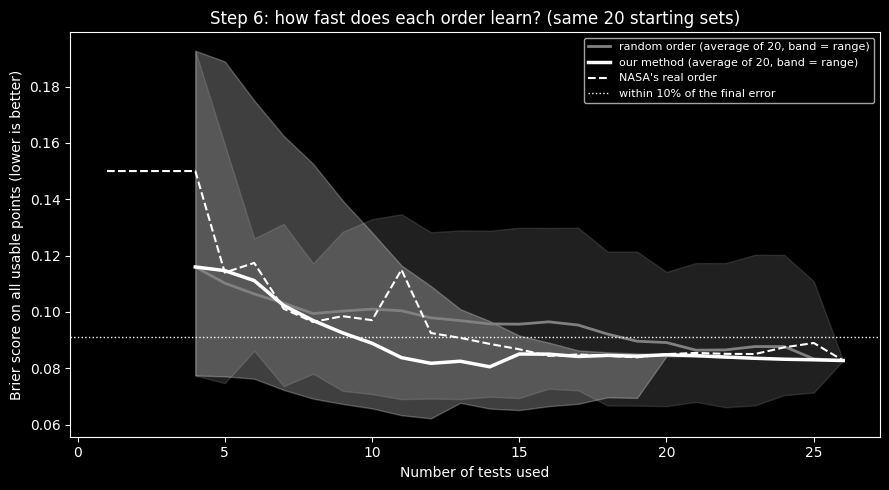

In [67]:
#-------------------------------------------------------------------------------
# how close to the final error counts as "there" (1.10 = within 10%)
target_ratio = 1.10
# band transparency
band_alpha = 0.25
#-------------------------------------------------------------------------------

# make a figure
fig, ax = plt.subplots(figsize=(9, 5))
# random order: band and average
ax.fill_between(x_tests, random_curves.min(axis=0), random_curves.max(axis=0), color='grey', alpha=band_alpha)
ax.plot(x_tests, random_curves.mean(axis=0), color='grey', linewidth=2, label=f'random order (average of {n_starts}, band = range)')
# our method: band and average
ax.fill_between(x_tests, ours_curves.min(axis=0), ours_curves.max(axis=0), color='white', alpha=band_alpha)
ax.plot(x_tests, ours_curves.mean(axis=0), color='white', linewidth=2.5, label=f'our method (average of {n_starts}, band = range)')
# NASA's real order
ax.plot(*zip(*nasa_curve), color='white', linestyle='--', linewidth=1.5, label="NASA's real order")
# the target line
ax.axhline(final_brier * target_ratio, color='white', linestyle=':', linewidth=1,
           label=f'within {round((target_ratio - 1) * 100)}% of the final error')
# labels, title and legend
ax.set_xlabel('Number of tests used')
ax.set_ylabel('Brier score on all usable points (lower is better)')
ax.set_title('Step 6: how fast does each order learn? (same 20 starting sets)')
ax.legend(fontsize=8)
# stop labels overlapping
fig.tight_layout()
# show the plot, then close it
plt.show()
plt.close()

**Finding:** Averaged over 20 starting sets, our method approaches the all-data model faster than random order and than NASA's real order (error measured on all 60 points, including those used in training). Its band of runs is also narrower: it is more consistent.

Here we:
- work out the **headline numbers**: how many tests each order needs before the model's error is within 10% of the final model's error **and stays there** (a curve that dips under the target and bounces back doesn't count)
- the first-dip numbers are printed too, for comparison
- for our method and random order: the average over the 20 starting sets, the range, and how often our method needed fewer tests **from the same start** (a paired comparison)

In [68]:
#-------------------------------------------------------------------------------
# same target as the plot
target = final_brier * target_ratio
#-------------------------------------------------------------------------------

def tests_needed(curve):
    # number of tests after which the error STAYS at or below the target until the end
    # (stricter than the first dip below it: a curve that dips and bounces back up doesn't count)
    ok = [b <= target for _, b in curve]
    for k in range(len(curve)):
        if all(ok[k:]):
            return curve[k][0]
    # never stays there
    return np.nan

def first_crossing(curve):
    # the first number of tests at which the error dips to or below the target (kept for comparison)
    for n, b in curve:
        if b <= target:
            return n
    return np.nan

# tests needed in every run, by both rules
ours_n = np.array([tests_needed(run[0]) for run in ours_runs], dtype=float)
random_n = np.array([tests_needed(run) for run in random_runs], dtype=float)
nasa_n = tests_needed(nasa_curve)
ours_first = np.array([first_crossing(run[0]) for run in ours_runs], dtype=float)
random_first = np.array([first_crossing(run) for run in random_runs], dtype=float)
nasa_first = first_crossing(nasa_curve)

# paired comparison: same start, which needed fewer? (stays-within rule)
fewer, same, more = int((ours_n < random_n).sum()), int((ours_n == random_n).sum()), int((ours_n > random_n).sum())

# print the numbers
print(f"Target: Brier <= {target:.4f} (final {final_brier:.4f} + 10%)\n")
print("Rule: stays within the target from then on (headline)")
print(f"  Our method:   {np.nanmean(ours_n):.1f} tests on average (range {np.nanmin(ours_n):.0f}-{np.nanmax(ours_n):.0f})")
print(f"  Random order: {np.nanmean(random_n):.1f} tests on average (range {np.nanmin(random_n):.0f}-{np.nanmax(random_n):.0f})")
print(f"  NASA's order: {nasa_n:.0f} tests")
print(f"  Same start, our method vs random: fewer tests in {fewer}, same in {same}, more in {more} of {n_starts}")
print(f"  Our method needed {100 * (np.nanmean(random_n) - np.nanmean(ours_n)) / np.nanmean(random_n):.0f}% fewer tests than random order "
      f"on average, and {100 * (nasa_n - np.nanmean(ours_n)) / nasa_n:.0f}% fewer than NASA's order.")
print("\nRule: first dip below the target (for comparison)")
print(f"  Our method {np.nanmean(ours_first):.1f} | random {np.nanmean(random_first):.1f} | NASA {nasa_first:.0f}")

Target: Brier <= 0.0910 (final 0.0827 + 10%)

Rule: stays within the target from then on (headline)
  Our method:   11.2 tests on average (range 4-16)
  Random order: 17.9 tests on average (range 6-26)
  NASA's order: 13 tests
  Same start, our method vs random: fewer tests in 15, same in 2, more in 3 of 20
  Our method needed 38% fewer tests than random order on average, and 14% fewer than NASA's order.

Rule: first dip below the target (for comparison)
  Our method 8.9 | random 14.3 | NASA 13


**Finding:** Our method's error is within 10% of the all-data model's, **and stays there**, after 11.2 tests on average (range 4–16), against 17.9 for random order (6–26) and 13 for NASA's real order: **38% fewer tests than random and 14% fewer than NASA's order**. From the same start it needed fewer tests than random in 15 of 20 runs (same in 2, more in 3). By the looser first-dip rule: 8.9 vs 14.3 vs 13. This validates the Refine part only; the replay can't test above 22% O₂.

Here we:
- plot the **track record** of the locked predictions, pooled over all 20 runs:
  - left: at each step, the share of points called right, and the share where the 90% range allowed the truth
  - right: the trust radius in every run (thin lines) and the average (thick line)

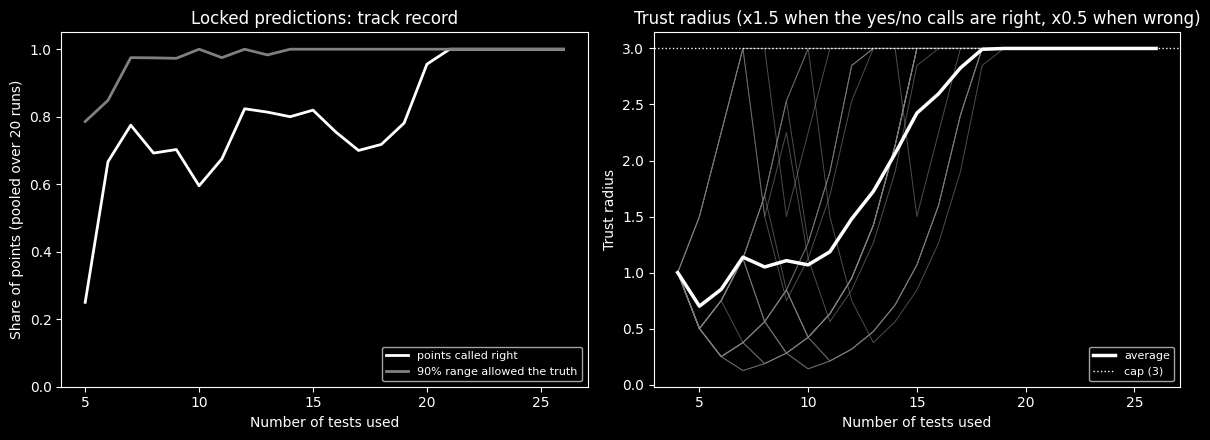

Locked predictions, all runs: 80% of points called right; 90% range allowed the truth for 98%


In [69]:
#-------------------------------------------------------------------------------
# line colours
accuracy_colour = 'white'
coverage_colour = 'grey'
#-------------------------------------------------------------------------------

# share right and share covered at each step, pooled over all runs
by_step = locked_all.groupby('step')[['right', 'range_allows_truth']].mean()

# make a figure with two panels
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5))
# left: accuracy and coverage per step
ax1.plot(by_step.index, by_step['right'], color=accuracy_colour, linewidth=2, label='points called right')
ax1.plot(by_step.index, by_step['range_allows_truth'], color=coverage_colour, linewidth=2,
         label='90% range allowed the truth')
ax1.set_ylim(0, 1.05)
ax1.set_xlabel('Number of tests used')
ax1.set_ylabel(f'Share of points (pooled over {n_starts} runs)')
ax1.set_title('Locked predictions: track record')
ax1.legend(fontsize=8, loc='lower right')
# right: radius in every run, then the average
radius_arr = np.array([[r for _, r in run[2]] for run in ours_runs])
for row in radius_arr:
    ax2.plot(x_tests, row, color='grey', linewidth=0.7, alpha=0.6)
ax2.plot(x_tests, radius_arr.mean(axis=0), color='white', linewidth=2.5, label='average')
ax2.axhline(radius_cap, color='white', linestyle=':', linewidth=1, label=f'cap ({radius_cap:g})')
ax2.set_xlabel('Number of tests used')
ax2.set_ylabel('Trust radius')
ax2.set_title('Trust radius (x1.5 when the yes/no calls are right, x0.5 when wrong)')
ax2.legend(fontsize=8)
# stop labels overlapping
fig.tight_layout()
# show the plot, then close it
plt.show()
plt.close()

# print the totals
print(f"Locked predictions, all runs: {locked_all['right'].mean():.0%} of points called right; "
      f"90% range allowed the truth for {locked_all['range_allows_truth'].mean():.0%}")

**Finding:** Pooled over 20 runs, 80% of the locked yes/no calls were right, and the 90% range never ruled out the true outcome in 98% of cases (wide ranges make the second number easy to pass, so it isn't a calibration measure). Late-run accuracy is flattered because the method picks the hard, near-boundary tests first. The trust radius shrinks after wrong calls and grows to its cap as calls come true.

Here we:
- look inside **one run** (the first starting set) step by step: which test was added, whether its yes/no calls were right, the radius, and the error on all points after adding it
- this explains the bumps in a single curve, e.g. a step where adding a test makes the error jump

In [70]:
#-------------------------------------------------------------------------------
# which run to look inside (0 = the first starting set)
run_to_show = 0
#-------------------------------------------------------------------------------

# the chosen run's curve, locked predictions and radius history
curve0, locked0, radius0, order0 = ours_runs[run_to_show]
# one row per step: test added, its points and flame-outs, share called right
steps = locked0.groupby('step').agg(test_added=('test_id', 'first'), points=('burned', 'size'),
                                    flameouts=('burned', lambda b: int((b == 0).sum())),
                                    share_right=('right', 'mean')).reset_index()
# radius after the step, and the error after the test was added
steps['radius_after'] = [r for n, r in radius0[1:]]
steps['brier_after'] = [b for n, b in curve0[1:]]
# change in error caused by adding the test
steps['brier_change'] = steps['brier_after'].diff().fillna(steps['brier_after'].iloc[0] - curve0[0][1])

# print the starting set and the step table
print("Starting set:", start_sets[run_to_show])
print(steps.round(4).to_string(index=False))

Starting set: ['O14', 'O5a', 'O3b', 'O12']
 step test_added  points  flameouts  share_right  radius_after  brier_after  brier_change
    5        O21       1          0       1.0000        1.5000       0.1112        0.0016
    6         O9       2          1       0.5000        2.2500       0.1023       -0.0089
    7        O11       2          1       1.0000        3.0000       0.0936       -0.0087
    8        O5b       1          0       0.0000        1.5000       0.0900       -0.0036
    9        O8b       2          1       1.0000        2.2500       0.0833       -0.0067
   10        O16       1          0       0.0000        1.1250       0.0810       -0.0024
   11       O13b       2          0       0.0000        0.5625       0.0788       -0.0022
   12        O22       2          1       1.0000        0.8438       0.0724       -0.0064
   13         O7       2          1       1.0000        1.2656       0.0713       -0.0011
   14        O17       2          0       0.5000        1

**Finding:** In this run the method picks boundary tests with flame-outs early (O9, O11, O8b, O22, O7), and the error falls fastest then. Adding O1 at step 15 raises the error by 0.016: O1 burned at 1–2 cm/s near 22% O₂, which pulls the straight line. After step 17 the remaining tests are easy burns and the error barely changes.

---
# 15 Prediction registry
---

Here we:
- **lock** the registry: if `prediction_registry.csv` already exists it is **not** overwritten; the cell loads it and prints its SHA-256 and creation time instead. Switch `allow_overwrite` to `True` only on purpose
- otherwise (first run): set the seeds, build the registry and save it. Every row says what is burned (material, rod size and colour, flow geometry, gravity), the prediction, the 90% range, the yes/no rule used, a note and a caveat:
  - **Refine**: today's `next_experiment()` result
  - **Explore**: today's `explore_experiment()` result
  - **Frontier pressure pair**: 34% O₂ at 5 cm/s, at 8.2 psia (no prediction) and 14.7 psia (extrapolated)
- the call is labelled **toss-up** when the 90% range straddles the yes/no threshold, and **(extrapolated)** when the O₂ is above the highest tested

In [71]:
#-------------------------------------------------------------------------------
# name of the registry file
registry_file = in_folder(registry_file_name)
# overwrite an existing registry? keep False unless you deliberately want a new one
allow_overwrite = False
# what the predictions are about (the model was fitted on Olson's PMMA rods, concurrent flow, in microgravity)
burn_setup = {'material': 'PMMA rod', 'rod_diameter_in': 0.25, 'rod_colour': 'clear',
              'flow_geometry': 'concurrent (upstream ignition, Olson configuration)', 'gravity': 'microgravity'}
# note added to every row
pooled_note = 'model pooled 1/4-1/2 inch rods'
#-------------------------------------------------------------------------------

# import tools for the fingerprint and the clock
import hashlib
import datetime
import os

def file_sha256(path):
    # fingerprint of a file's exact bytes
    with open(path, 'rb') as fh:
        return hashlib.sha256(fh.read()).hexdigest()

if os.path.exists(registry_file) and not allow_overwrite:
    # LOCKED: load the existing registry and report it, without changing anything
    registry = pd.read_csv(registry_file, keep_default_na=False)   # keep empty cells empty (not 'nan')
    print(f"{registry_file} already exists and allow_overwrite is False: NOT overwritten.\n")
else:
    # seeds, so the registry is reproducible
    np.random.seed(seed)
    random.seed(seed)
    # the time the registry is made, in UTC
    created_utc = datetime.datetime.now(datetime.timezone.utc).isoformat(timespec='seconds')

    # the yes/no threshold on all usable points (weighted burn base rate), and the rule as text
    _, y_reg, w_reg = make_xyw(data)
    t_reg = burn_base_rate(y_reg, w_reg)
    call_rule = f"flame-out if P(burn) < {t_reg:.3f} (weighted burn base rate)"
    # highest O2 tested, for the extrapolation label
    o2_tested_max = data['o2_pct'].max()

    def call_label(p, lo, hi, o2):
        # toss-up when the 90% range straddles the threshold
        if lo < t_reg <= hi:
            return f"toss-up ({'burns' if p >= t_reg else 'flame-out'} by base-rate rule)"
        # otherwise the plain call, marked if the O2 is above anything tested
        label = 'burns' if p >= t_reg else 'flame-out'
        return label + (' (extrapolated)' if o2 > o2_tested_max else '')

    def row(track, o2, airflow, psia, p, lo, hi, call, note, caveat):
        # one registry row, with the burn set-up in front
        return {'track': track, **burn_setup, 'o2_pct': o2, 'airflow_cm_s': airflow, 'pressure_psia': psia,
                'platform': platform_name, 'p_burn': p, 'p_low_5': lo, 'p_high_95': hi, 'call': call,
                'call_rule': call_rule, 'note': f"{note}; {pooled_note}", 'caveat': caveat}

    # today's two recommendations, on all usable points with the starting radius
    ref = next_experiment(data, np.random.default_rng(seed), radius_start)
    exp = explore_experiment(data, np.random.default_rng(seed), radius_start)
    rows = []
    for track, a, note in [('Refine', ref, 'most disagreement x Moon relevance inside the trust region'),
                           ('Explore', exp, exp['note'])]:
        lo, hi = a['p_burn_90pct_range']
        rows.append(row(track, a['o2_pct'], a['airflow_cm_s'], a['pressure_psia'], a['p_burn'], lo, hi,
                        call_label(a['p_burn'], lo, hi, a['o2_pct']), note, prediction_caveat))

    # frontier pressure pair: shared note on the airflow choice
    airflow_note = (f"{frontier_airflow:g} cm/s = the standard BASS-II ignition airflow, "
                    "chosen so results compare directly with existing data")
    # 8.2 psia: no prediction
    rows.append(row('Frontier pressure pair', frontier_o2, frontier_airflow, 8.2, '', '', '', 'no prediction',
                    f"{frontier_label}; {airflow_note}", 'no prediction: reduced pressure not in the data'))
    # 14.7 psia: the number, clearly marked as extrapolated
    lo, hi = round(float(frontier_score['p_low_5']), 3), round(float(frontier_score['p_high_95']), 3)
    gap = frontier_o2 - o2_tested_max
    rows.append(row('Frontier pressure pair', frontier_o2, frontier_airflow, test_pressure_psia,
                    round(float(frontier_score['p_burn']), 3), lo, hi, call_label(float(frontier_score['p_burn']), lo, hi, frontier_o2),
                    (f"{frontier_o2:g}% is ~{gap:.0f} points of O2 above the highest tested; the 90% range can't show "
                     f"extrapolation uncertainty (every model extends the same straight line); {airflow_note}"),
                    prediction_caveat))

    # put the rows in a table, stamp the time on every row, and save
    registry = pd.DataFrame(rows)
    registry['created_utc'] = created_utc
    registry.to_csv(registry_file, index=False)
    print(f"Saved a new {registry_file}.\n")

# print the full registry, one row at a time so every column is readable
for i, r in registry.iterrows():
    print(f"--- row {i + 1} ---")
    for column, value in r.items():
        print(f"{column:>16}: {value}")
# the fingerprint and the creation time
print("\nSHA-256:", file_sha256(registry_file))
print("UTC time:", registry['created_utc'].iloc[0])

/content/drive/MyDrive/flame-in-freefall/prediction_registry.csv already exists and allow_overwrite is False: NOT overwritten.

--- row 1 ---
           track: Refine
        material: PMMA rod
 rod_diameter_in: 0.25
      rod_colour: clear
   flow_geometry: concurrent (upstream ignition, Olson configuration)
         gravity: microgravity
          o2_pct: 13.5
    airflow_cm_s: 8.67
   pressure_psia: 14.7
        platform: ISS (SoFIE, Combustion Integrated Rack)
          p_burn: 0.53
         p_low_5: 0.159
       p_high_95: 0.936
            call: toss-up (flame-out by base-rate rule)
       call_rule: flame-out if P(burn) < 0.875 (weighted burn base rate)
            note: most disagreement x Moon relevance inside the trust region; model pooled 1/4-1/2 inch rods
          caveat: at ISS cabin pressure (~14.7 psia); effect of reduced pressure not in the data
     created_utc: 2026-11-14T15:27:37+00:00
--- row 2 ---
           track: Explore
        material: PMMA rod
 rod_diameter_